<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QNN_AdversarialLearning_Ren2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum adversarial learning with a 10-qubit variational classifier: Ren et al. (2022) step by step

This notebook re-implements, runs and checks the simulation side of

> Wenhui Ren, Weikang Li, Shibo Xu, Ke Wang, Wenjie Jiang, Feitong Jin, Xuhao Zhu, Jiachen Chen, Zixuan Song, Pengfei Zhang,
> Hang Dong, Xu Zhang, Jinfeng Deng, Yu Gao, Chuanyu Zhang, Yaozu Wu, Bing Zhang, Qiujiang Guo, Hekang Li, Zhen Wang,
> Jacob Biamonte, Chao Song, Dong-Ling Deng and H. Wang, "Experimental quantum adversarial learning with programmable
> superconducting qubits", *Nature Computational Science* **2**, 711 (2022). DOI 10.1038/s43588-022-00351-9 (arXiv:2204.01738)

The authors trained variational quantum classifiers **on a ten-qubit superconducting chip**, fooled them with small
adversarial perturbations and then repaired them by adversarial training. Hardware cannot be rerun in a notebook. What can be
rerun is everything that is mathematics: the circuit (interleaved block encoding, `Rx`/`Rz` rotations and CNOT layers), the
exact quantum states of the Aubry-Andre model, the cross-entropy training with Adam and gradient groups, the white-box attacks
(gradient ascent on the loss) and adversarial training. The notebook simulates all of that exactly on a CPU, **checks the fast
simulator against a real Qiskit circuit**, and puts the paper's numbers next to its own. Every hardware-only claim
(gate fidelities, T1, dynamical decoupling) is marked "cannot be checked".

**What the notebook does.**
1. Downloads three real datasets (MedNIST *Hand* vs *BreastMRI*, MNIST digits 0 and 1, and generates the quantum data, which is
   an exact simulation of the paper's Hamiltonian) and shows them (first mandatory section below).
2. Builds the paper's circuits as Qiskit objects, draws them and proves that the fast PyTorch simulator computes the same numbers
   (second mandatory section below).
3. Trains the classifiers with the paper's recipe (parameter groups, Adam, mini-batches), attacks them with type-1 / type-2
   examples and with quantum-state perturbations, and repeats the **same attack with the same budget on classical models**
   (logistic regression, RBF-SVM, small MLP) on identical inputs.
4. Adds checks the paper does not contain: gradient-free and restart attacks to detect **gradient masking**, a fresh adaptive attack
   on the adversarially retrained model (the paper only tests a fixed set of examples made against the *original* model), a
   noisy-gate proxy for the device, and the paper's supplementary benchmark of "interleaved" against "encoding first" circuits.
5. Prints a per-claim table (reproduced / not reached / exceeded / cannot be checked).

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. `FAST_MODE = True` (default
in the configuration cell) is a class demo; set `FAST_MODE = False` for the full budgets. The first cell installs pinned
packages; if Colab asks to restart the session, do so and run all cells again. The data download needs internet access (about 62 MB
streamed once for MedNIST, 20 MB for MNIST, none of it stored in full). MNIST and Fashion-MNIST come from public Hugging Face
datasets; no token is required, but if you have one, put it in Colab *Secrets* as `HF_TOKEN` (the notebook never prints it).

**What you get at the end.** The paper's Fig. 2c-f, Fig. 3b-d, Fig. 4a-b and Fig. S2-S5, S13 redrawn from your own runs, a table of
accuracy against attack budget for quantum and classical models, and the verdict table.

## The paper in one page

**Problem.** Quantum classifiers, like deep networks, can be fooled by tiny, deliberately chosen input changes (adversarial examples).
The paper asks whether this can be shown in a real experiment and whether adversarial training helps.

**Decision.** Binary classification; the class is read from the sign of the expectation value $\langle\sigma_z\rangle$ of qubit Q5
($\ge 0$: first class, $< 0$: second class). The probabilities are $g_1 = (1+\langle\sigma_z\rangle)/2$, $g_2 = (1-\langle\sigma_z\rangle)/2$ and the loss
is the cross entropy $L = -\sum_k a_k \log g_k$ (Eq. 1).

**Method (Fig. 2b, Fig. S8, Fig. S9).**
- *Classical images:* the "interleaved block-encoding" circuit. The image is compressed to 16 x 16 pixels, flattened to 256 numbers, padded with
  four zeros to 260 numbers and each number is added to one trainable parameter to form the angle of one single-qubit rotation
  (alternating $R_x$, $R_z$). Four blocks (8, 6, 6, 6 rotation layers on 10 qubits) each end with two layers of CNOT gates on a chain
  (260 rotations, 260 trainable parameters, circuit depth up to 60 after compilation to the hardware gate set).
- *Quantum data:* ground-state-like states made by evolving the Neel state for 400 ns under the Aubry-Andre Hamiltonian
  $H/\hbar = -\tfrac{g}{2}\sum_k(\sigma^x_k\sigma^x_{k+1}+\sigma^y_k\sigma^y_{k+1}) - \sum_k \tfrac{V_k}{2}\sigma^z_k$, $V_k = V\cos(2\pi\alpha k + \varphi)$,
  $\alpha=(\sqrt5-1)/2$. Thermal states: $V/g\in[0,1]$; localized states: $V/g\in[4,5]$; random phase $\varphi$. The classifier has five
  blocks of three single-qubit rotations per qubit and two CNOT layers (150 parameters).
- *Training:* the parameters are cut into ten groups (one per qubit row); in each epoch every group in turn takes one Adam step
  (learning rate 0.05) from the gradient of a random mini-batch of 20 training samples (parameter-shift rule on the device).
- *Attack (untargeted, white box):* $\delta = \arg\max_{\delta'\in\Delta} L(h(x+\delta';\theta^*),a)$ (Eq. 2) by Adam gradient ascent on the input.
  Type-1 examples perturb the whole image, type-2 examples only the area occupied by the object. For quantum data the "perturbation"
  is a layer of three small rotations $R_x(\delta_1)R_z(\delta_2)R_x(\delta_3)$, $|\delta_i|\le 0.5$, applied to every qubit of the Neel state
  *before* the Hamiltonian evolution (Algorithm 8).
- *Defence:* adversarial training. One adversarial example per training sample is generated against the trained model, the 260
  parameters are re-initialised and training is repeated on the union of legitimate and adversarial samples (10 + 10 per batch).

**Data.** (i) "Hand" and "Breast" images of the medical MNIST (MedNIST) collection, 500 training and 100 test images;
(ii) MNIST digits 0 and 1, 500 / 100, only 50 parameters trained (lr 0.02, 5 + 5 per adversarial batch); (iii) 500 / 100 quantum states.
Supplementary benchmark (Fig. S2-S5): 540-rotation circuits, MNIST and Fashion-MNIST, 1000 / 400 samples, lr 0.003, "interleaved" against "encoding first".

**Claims that can be checked in simulation** (hardware values in parentheses are the paper's):
1. MRI Hand/Breast: train accuracy 0.92 and test accuracy 0.97 after 20 epochs (about 0.96 test accuracy after 5 epochs; "up to 99 %" in the abstract).
2. MNIST 0/1: train 0.98, test 0.99.
3. Type-1 adversarial examples of the whole MRI test set are all misclassified (Fig. 2f).
4. Quantum data: near-perfect train and test accuracy after about 30 steps; on 20 chosen legitimate states all are right; under attack all
   localized and half of the thermal states are misclassified (Fig. 3d); the perturbed states keep the local-magnetization signature of their phase.
5. Adversarial training: accuracy on both legitimate and adversarial MRI test images approaches 1 after about 25 epochs (Fig. 4a); on MNIST the
   retrained classifier "defends certain attacks better" (Fig. S13d).
6. Supplementary: the interleaved structure beats the encoding-first structure in simulation (Fig. S2-S5).
7. Hardware only (cannot be checked here): T1 about 150 us, single/two-qubit gate fidelity above 99.94 % / 99.4 %, adversarial examples made on a classical computer still fool the noisy device.

### What follows the paper and what had to be chosen

The paper gives code only "on reasonable request". Everything below the line "This notebook" is a choice made here and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Hardware | 10 transmon qubits, device noise, readout correction | exact noiseless statevector simulation (PyTorch), checked against Qiskit; a depolarizing-noise proxy with the paper's gate errors in Aer |
| Gradients | parameter-shift rule measured on the device | exact autograd gradients (identical in expectation); parameter-shift agreement is tested |
| Medical data | "Hand" / "Breast" MRI from the medical MNIST [30] | MedNIST (MONAI release of the same collection, 64 x 64): *Hand* (X-ray) vs *BreastMRI*, 16 x 16 area-averaged, scaled to [0, 1] |
| Sizes | 500 train / 100 test | the same in the full run; smaller in `FAST_MODE` |
| "factor of two" in the angle map | pixels "normalized and mapped into the rotation angles by a factor of two" | angle = `X_SCALE` * pixel + theta, `X_SCALE` chosen on a validation split of the training data from {0.5, 1, 2} |
| Initial parameters | "randomly generated" | uniform on [0, 2 pi) or normal(0, 0.3), chosen on the same validation split |
| Block layout | 4 blocks, 8/6/6/6 rotation layers of Rx, Rz, 2 CNOT layers per block | alternating Rx, Rz layers starting with Rx, CNOT layers (Q1,Q2),(Q3,Q4)... then (Q2,Q3),(Q4,Q5)..., read-out Q5 |
| Training | Adam, lr 0.05, 10 groups, 20 train samples per group step, 20 epochs | the same; per-epoch accuracy is computed exactly on the full test set and a fixed 200-sample subset of the training set |
| Attack budget Delta | "a small region", not specified | l-infinity ball of radius `EPS` on the [0, 1] pixel scale (headline `EPS_MAIN`) around the legitimate image, pixels kept in [0, 1], the four padding zeros untouched; budget sweep reported |
| Attack optimiser | Adam gradient ascent | Adam gradient ascent with projection, keeps the strongest iterate; plus restarts and a gradient-free SPSA attack |
| Type-2 mask | "area where the object lies" | pixels with intensity above 0.1 in the legitimate image |
| Adversarial training | re-initialise, 10 + 10 per batch, same lr | the same; adversarial set made against the original model (type-1) as in the paper, then also tested by a fresh attack |
| MNIST | digits 0, 1, 500 / 100, 50 parameters in layers 3, 6, 11, 17, 23, lr 0.02 | the same; 28 x 28 -> 16 x 16 by area averaging; one Adam step per iteration |
| Quantum data | Neel state, 400 ns, g/2pi = 5 MHz, V/g in [0,1] or [4,5] | Neel state with Q1, Q3, Q5, Q7, Q9 excited; exact evolution in particle-number sectors (asserted against `scipy.linalg.expm` of the Qiskit Hamiltonian); g = 1, g tau = 4 pi |
| Quantum classifier | 5 blocks x 3 rotations per qubit + 2 CNOT layers, 150 parameters | `Rx Rz Rx` per block; lr 0.05, 10 groups of 15 parameters |
| Quantum perturbation | `Rx(d1) Rz(d2) Rx(d3)`, d_i in [-0.5, 0.5], Adam | d_i = 0.5 sin(psi_i), psi initialised at 0 (identity), Adam ascent |
| Shots / readout error | measured, readout-corrected | expectation values are exact (no shot noise) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and PyTorch.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit / qiskit-aer already present; skipping pip install.")

qiskit / qiskit-aer already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo (reduced data sets and attack budgets; about 30 minutes on a laptop CPU). False: the paper's sizes and budgets (the else-branch below; about 3 hours).
SEED = 42                   # every random number generator below derives from this
DATA_DIR = "qc315_data"     # downloaded data is cached here (small .npz files)
IBM_TOKEN = ""              # unused: this notebook never contacts real hardware (the paper's chip is not available)

if FAST_MODE:
    N_TR_PC, N_TE_PC = 100, 30       # images per class: train / test (paper: 250 / 50 per class = 500 / 100)
    EPOCHS_MED = 20                  # paper: 20 epochs
    EPOCHS_ADV = 25                  # paper: accuracy approaches 1 after about 25 epochs of adversarial training
    N_SEEDS = 2                      # independent repetitions (data split, initial parameters, mini-batches)
    ATTACK_STEPS = 12                # Adam ascent steps of the white-box attack
    N_RESTARTS = 2                   # random restarts of the attack used in the gradient-masking check
    SPSA_ITERS = 30                  # gradient-free attack iterations
    EPS_GRID = [0.05, 0.1, 0.2]
    DIAG_N = 24                      # balanced test subset for the attack ladder and the budget sweep
    SWEEP_EPOCHS, SWEEP_POOL = 3, 120 # validation sweep of the angle scale / initialisation (pool of training images, split 75/25)
    SWEEP_CFGS = [(1.0, 0.3), (2.0, None)]
    STEPS_MNIST = 200                # paper: about 200 Adam steps
    NQ_TR_PC, NQ_TE_PC = 80, 25      # quantum states per class: train / test (paper: 250 / 50)
    EPOCHS_Q = 30                    # paper: near-perfect after about 30 steps
    QATK_STEPS = 20                  # steps of the quantum-state attack
    N_NOISE = 8                      # test images simulated with gate noise
    ABL_NTR, ABL_NTE, ABL_STEPS, ABL_SEEDS = 120, 60, 40, 1
else:
    N_TR_PC, N_TE_PC = 250, 50
    EPOCHS_MED = 20
    EPOCHS_ADV = 25
    N_SEEDS = 3
    ATTACK_STEPS = 20
    N_RESTARTS = 3
    SPSA_ITERS = 60
    EPS_GRID = [0.02, 0.05, 0.1, 0.2]
    DIAG_N = 60
    SWEEP_EPOCHS, SWEEP_POOL = 6, 300
    SWEEP_CFGS = [(2.0, None), (2.0, 0.3), (1.0, 0.3), (1.0, None)]
    STEPS_MNIST = 200
    NQ_TR_PC, NQ_TE_PC = 250, 50
    EPOCHS_Q = 30
    QATK_STEPS = 40
    N_NOISE = 30
    ABL_NTR, ABL_NTE, ABL_STEPS, ABL_SEEDS = 300, 150, 100, 1
EPS_MAIN = 0.1              # CHOICE: headline l-infinity attack budget (fraction of the grey range); the paper does not state one
LR_MED, BATCH_MED = 0.05, 20        # paper: learning rate 0.05, 20 training samples per group step
LR_MNIST, BATCH_MNIST = 0.02, 10    # paper: learning rate 0.02, 10 samples per step (5 + 5 in adversarial training)
LR_Q, BATCH_Q = 0.05, 20            # CHOICE: the paper gives no learning rate for the quantum-data classifier; same as for the medical task
KAPPA = 0.5                         # paper: perturbation angles bounded by 0.5
print("FAST_MODE =", FAST_MODE, "| seeds:", N_SEEDS, "| train/test per class:", N_TR_PC, N_TE_PC, "| epochs:", EPOCHS_MED)

FAST_MODE = True | seeds: 2 | train/test per class: 100 30 | epochs: 20


In [3]:
import os, io, time, math, warnings, json, dataclasses
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import torch
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import qiskit, qiskit_aer

os.makedirs(DATA_DIR, exist_ok=True)
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)             # one thread: reproducible and friendly to shared machines
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2 | qiskit-aer 0.17.2


## Dataset Exploration and Visualisation

Three real datasets are used. Nothing is simulated except the quantum data, which *is* a simulation by definition in the paper (the
chip prepares those states; here the exact same states are computed from the paper's Hamiltonian). No labels are invented and no
unrelated data set is substituted.

| Task | Data | Classes (original labels) | Source |
|---|---|---|---|
| A. medical images | MedNIST, 64 x 64 greyscale | `Hand` (X-ray) = 0, `BreastMRI` = 1 | MONAI release of A. Polanco's "Medical MNIST" (images from TCIA, RSNA bone age, ChestX-ray8; the paper's refs 30-33) |
| B. digits | MNIST, 28 x 28 greyscale | digit `0` = 0, digit `1` = 1 | Hugging Face `ylecun/mnist` |
| C. quantum states | 10-qubit states $e^{-iH\tau}\lvert\text{Neel}\rangle$ | thermal ($V/g\in[0,1]$) = 0, localized ($V/g\in[4,5]$) = 1 | generated from the paper's Eq. 3 |
| D. ablation (Fig. S2-S5) | MNIST and Fashion-MNIST, digits / classes 0 and 1 | 0 / 1 (Fashion-MNIST: T-shirt/top = 0, trouser = 1) | Hugging Face `ylecun/mnist`, `zalando-datasets/fashion_mnist` |

The paper compresses every image to 16 x 16 pixels (area averaging here), scales it to [0, 1], flattens it to 256 numbers and appends four
zeros, giving the 260 numbers that become rotation angles. The two cells below download and split the images; the splits are
stratified and repeated per seed (seed 0 is the one drawn in the figures).

In [4]:
import io, tarfile, requests
from PIL import Image


def hf_token():
    """Token only from the environment or Colab Secrets; never printed or stored."""
    tok = os.environ.get("HF_TOKEN")
    if tok is None:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            tok = None
    return tok


def load_mednist_pair(data_dir, per_class=1000, seed=42):
    """MedNIST (the MONAI release of A. Polanco's 'Medical MNIST', 64x64 images from TCIA / RSNA bone age / ChestX-ray8).
    The 62 MB archive is streamed once; only 'Hand' (X-ray) and 'BreastMRI' are kept (per_class random images each) in a small .npz cache."""
    npz = os.path.join(data_dir, "mednist_hand_breast.npz")
    if not os.path.exists(npz):
        url = "https://github.com/Project-MONAI/MONAI-extra-test-data/releases/download/0.8.1/MedNIST.tar.gz"
        r = requests.get(url, stream=True, timeout=120); r.raise_for_status()
        tf = tarfile.open(fileobj=r.raw, mode="r|gz")
        pool = {"Hand": [], "BreastMRI": []}
        for m in tf:
            if m.isfile() and m.name.split("/")[-2] in pool:
                pool[m.name.split("/")[-2]].append((m.name.split("/")[-1], np.array(Image.open(io.BytesIO(tf.extractfile(m).read())).convert("L"))))
        rng_ = np.random.default_rng(seed); out = {}
        for cls, lst in pool.items():
            lst = sorted(lst, key=lambda t: t[0]); pick = sorted(rng_.choice(len(lst), per_class, replace=False))
            out[cls] = np.stack([lst[i][1] for i in pick]); out[cls + "_names"] = np.array([lst[i][0] for i in pick])
        np.savez_compressed(npz, **out)
    z = np.load(npz)
    return z["Hand"], z["BreastMRI"], z["Hand_names"], z["BreastMRI_names"]


def load_hf_image_dataset(repo, data_dir, classes, per_class_train, per_class_test, seed=42, label_col="label"):
    """MNIST (ylecun/mnist) or Fashion-MNIST (zalando-datasets/fashion_mnist) from the Hugging Face parquet files; keeps two classes."""
    from huggingface_hub import hf_hub_download
    sub = repo.split("/")[1]
    out = {}
    for split in ("train", "test"):
        local = os.path.join(data_dir, f"{sub}_{split}_{classes[0]}{classes[1]}.npz")
        if not os.path.exists(local):
            pq = hf_hub_download(repo, f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset", token=hf_token(), local_dir=os.path.join(data_dir, "hf"))
            df = pd.read_parquet(pq)
            df = df[df[label_col].isin(classes)]
            imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"])).convert("L")) for d in df["image"]])
            np.savez_compressed(local, X=imgs, y=df[label_col].to_numpy())
            os.remove(pq)
        zz = np.load(local); out[split] = (zz["X"], zz["y"])
    rng_ = np.random.default_rng(seed)
    res = {}
    for split, n in (("train", per_class_train), ("test", per_class_test)):
        X, y = out[split]; sel = []
        for c in classes:
            ii = np.where(y == c)[0]; sel.append(rng_.choice(ii, n, replace=False))
        sel = np.concatenate(sel); res[split] = (X[sel], (y[sel] == classes[1]).astype(int))
    return res


def to_input_vectors(imgs, side=16, pad_to=260):
    """Paper: compress to 16 x 16 pixels (area averaging), scale to [0, 1], flatten to 256 numbers, append four zeros -> 260 rotation angles."""
    t = torch.tensor(imgs, dtype=torch.float64).unsqueeze(1) / 255.0
    small = torch.nn.functional.interpolate(t, size=(side, side), mode="area").squeeze(1)
    flat = small.reshape(len(imgs), -1)
    return torch.cat([flat, torch.zeros(len(imgs), pad_to - flat.shape[1], dtype=torch.float64)], 1)


def image_task_split(pool0, pool1, n_tr, n_te, seed):
    """Random disjoint train / test draw of n_tr and n_te images per class from the pools of class 0 and class 1."""
    r = np.random.default_rng(seed); out = {}
    ia, ib = r.permutation(len(pool0)), r.permutation(len(pool1))
    for name, sl in (("tr", slice(0, n_tr)), ("te", slice(n_tr, n_tr + n_te))):
        a, b = pool0[ia[sl]], pool1[ib[sl]]
        imgs = np.concatenate([a, b]); y = np.r_[np.zeros(len(a)), np.ones(len(b))]
        out["imgs_" + name], out["y" + name], out["X" + name] = imgs, torch.tensor(y), to_input_vectors(imgs)
    return out


t0 = time.time()
HAND, BREAST, HAND_NAMES, BREAST_NAMES = load_mednist_pair(DATA_DIR, per_class=1000, seed=SEED)
print(f"MedNIST Hand {HAND.shape}, BreastMRI {BREAST.shape}  ({time.time()-t0:.0f} s)")
MN = load_hf_image_dataset("ylecun/mnist", DATA_DIR, (0, 1), per_class_train=500, per_class_test=100, seed=SEED)
print("MNIST 0/1 train", MN["train"][0].shape, "test", MN["test"][0].shape, f"({time.time()-t0:.0f} s)")


def med_split(seed):
    return image_task_split(HAND, BREAST, N_TR_PC, N_TE_PC, seed)


def mnist_split(seed):
    """Training images from the official MNIST training set, test images from the official test set (as in a standard MNIST protocol)."""
    r = np.random.default_rng(seed); out = {}
    for name, (X, y), n in (("tr", MN["train"], N_TR_PC), ("te", MN["test"], N_TE_PC)):
        sel = np.concatenate([r.permutation(np.where(y == c)[0])[:n] for c in (0, 1)])
        out["imgs_" + name], out["y" + name], out["X" + name] = X[sel], torch.tensor(y[sel].astype(float)), to_input_vectors(X[sel])
    return out


MED = med_split(SEED); MNI = mnist_split(SEED)
print("task A (medical): train", tuple(MED["Xtr"].shape), "test", tuple(MED["Xte"].shape))
print("task B (MNIST)  : train", tuple(MNI["Xtr"].shape), "test", tuple(MNI["Xte"].shape))

MedNIST Hand (1000, 64, 64), BreastMRI (1000, 64, 64)  (0 s)


MNIST 0/1 train (1000, 28, 28) test (200, 28, 28) (4 s)
task A (medical): train (200, 260) test (60, 260)
task B (MNIST)  : train (200, 260) test (60, 260)


### Task A and B: shapes, features, labels, class balance, example images

For every image dataset the next cell prints the shape of the model input, the names of the 260 input features (256 pixels plus 4
padding zeros), the original label values and the class counts, then draws the class distribution (bar chart) and a gallery of real
images with their 16 x 16 versions, which are what the circuit really sees.

=== Task A: MedNIST Hand vs BreastMRI ===
train input matrix: (200, 260) | test input matrix: (60, 260) | raw image size: (64, 64)
feature names: ['px_r00_c00', 'px_r00_c01', 'px_r00_c02'] ... ['px_r15_c14', 'px_r15_c15', 'pad_0', 'pad_1', 'pad_2', 'pad_3'] (260 in total; the last 4 are the paper's zero padding)
original labels: {'Hand': 0, 'BreastMRI': 1}
  train class counts: {'Hand': 100, 'BreastMRI': 100}
  test  class counts: {'Hand': 30, 'BreastMRI': 30}
pixel statistics of the model input (train): mean 0.189, std 0.266, range [0.00, 1.00]


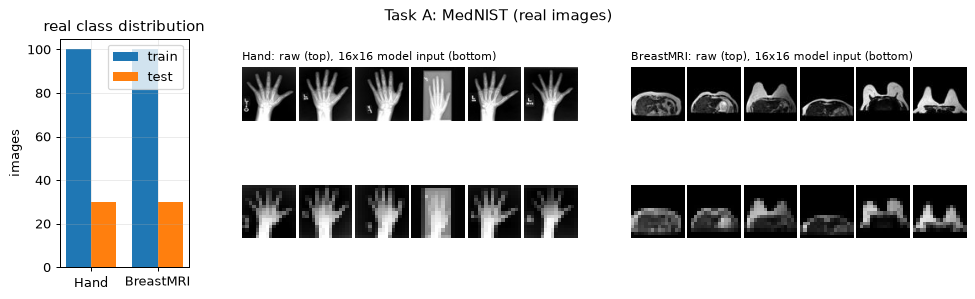

=== Task B: MNIST digits 0 and 1 ===
train input matrix: (200, 260) | test input matrix: (60, 260) | raw image size: (28, 28)
feature names: ['px_r00_c00', 'px_r00_c01', 'px_r00_c02'] ... ['px_r15_c14', 'px_r15_c15', 'pad_0', 'pad_1', 'pad_2', 'pad_3'] (260 in total; the last 4 are the paper's zero padding)
original labels: {'0': 0, '1': 1}
  train class counts: {'digit 0': 100, 'digit 1': 100}
  test  class counts: {'digit 0': 30, 'digit 1': 30}
pixel statistics of the model input (train): mean 0.127, std 0.268, range [0.00, 1.00]


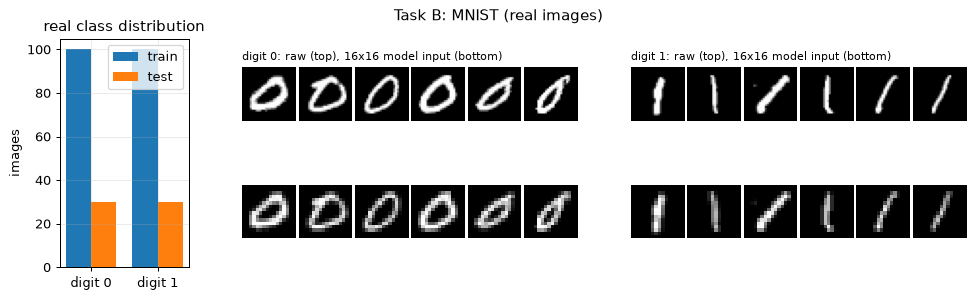

In [5]:
FEATURE_NAMES = [f"px_r{r:02d}_c{c:02d}" for r in range(16) for c in range(16)] + [f"pad_{i}" for i in range(4)]


def describe_image_task(title, D, names, label_values):
    print(f"=== {title} ===")
    print("train input matrix:", tuple(D["Xtr"].shape), "| test input matrix:", tuple(D["Xte"].shape), "| raw image size:", D["imgs_tr"].shape[1:])
    print("feature names:", FEATURE_NAMES[:3], "...", FEATURE_NAMES[254:], f"({len(FEATURE_NAMES)} in total; the last 4 are the paper's zero padding)")
    print("original labels:", label_values)
    for split in ("tr", "te"):
        yy = D["y" + split].numpy().astype(int)
        print(f"  {'train' if split=='tr' else 'test '} class counts:", {names[k]: int((yy == k).sum()) for k in (0, 1)})
    print(f"pixel statistics of the model input (train): mean {D['Xtr'][:, :256].mean():.3f}, std {D['Xtr'][:, :256].std():.3f}, range [{D['Xtr'][:, :256].min():.2f}, {D['Xtr'][:, :256].max():.2f}]")


def plot_distribution_and_gallery(title, D, names, cmap="gray"):
    fig = plt.figure(figsize=(13, 3.3))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.0, 2.6, 2.6])
    ax = fig.add_subplot(gs[0]); w = 0.38
    for j, (split, lab) in enumerate((("tr", "train"), ("te", "test"))):
        cnt = np.bincount(D["y" + split].numpy().astype(int), minlength=2)
        ax.bar(np.arange(2) + (j - 0.5) * w, cnt, w, label=lab)
    ax.set_xticks([0, 1]); ax.set_xticklabels(names); ax.set_ylabel("images"); ax.set_title("real class distribution"); ax.legend()
    for k, (cls, gsp) in enumerate(((0, gs[1]), (1, gs[2]))):
        sub = gsp.subgridspec(2, 6, wspace=0.05, hspace=0.05)
        idx = np.where(D["ytr"].numpy() == cls)[0][:6]
        for i, ii in enumerate(idx):
            a = fig.add_subplot(sub[0, i]); a.imshow(D["imgs_tr"][ii], cmap=cmap); a.axis("off")
            b = fig.add_subplot(sub[1, i]); b.imshow(D["Xtr"][ii, :256].reshape(16, 16).numpy(), cmap=cmap, vmin=0, vmax=1); b.axis("off")
            if i == 0: a.set_title(f"{names[cls]}: raw (top), 16x16 model input (bottom)", loc="left", fontsize=9)
    fig.suptitle(title); plt.show()


describe_image_task("Task A: MedNIST Hand vs BreastMRI", MED, ["Hand", "BreastMRI"], {"Hand": 0, "BreastMRI": 1})
plot_distribution_and_gallery("Task A: MedNIST (real images)", MED, ["Hand", "BreastMRI"])
describe_image_task("Task B: MNIST digits 0 and 1", MNI, ["digit 0", "digit 1"], {"0": 0, "1": 1})
plot_distribution_and_gallery("Task B: MNIST (real images)", MNI, ["digit 0", "digit 1"])

### Task A and B: where the real images sit (labelled 2-D projection)

A 10-qubit circuit with 260 angles cannot be drawn as a point in the plane, so we project the real 256-pixel vectors onto their first two
principal components. **Every point is a real image coloured by its true class.** The PCA is fitted on the training split only; test
images are projected with the same transform (crosses). The second panel scales the same coordinates to $[0,\pi]$ (min-max fitted on
the training split, test values clipped), the range an angle encoding would use. The classifier itself encodes all 256 pixels, not these two numbers.

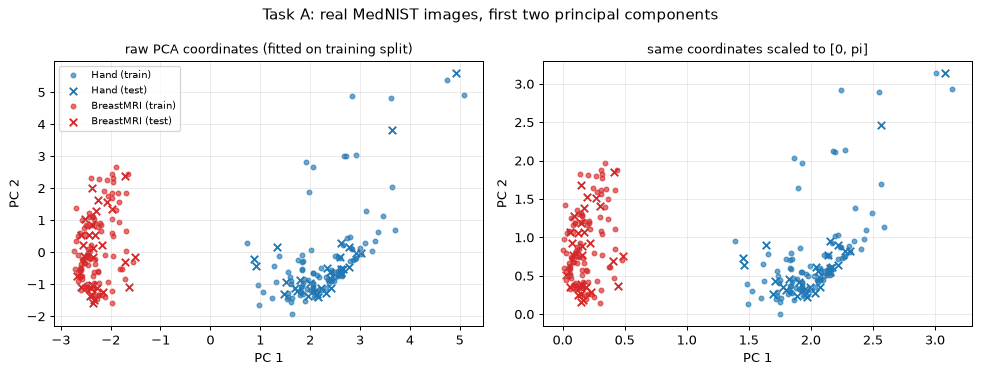

explained variance of PC1, PC2: [0.435 0.135]


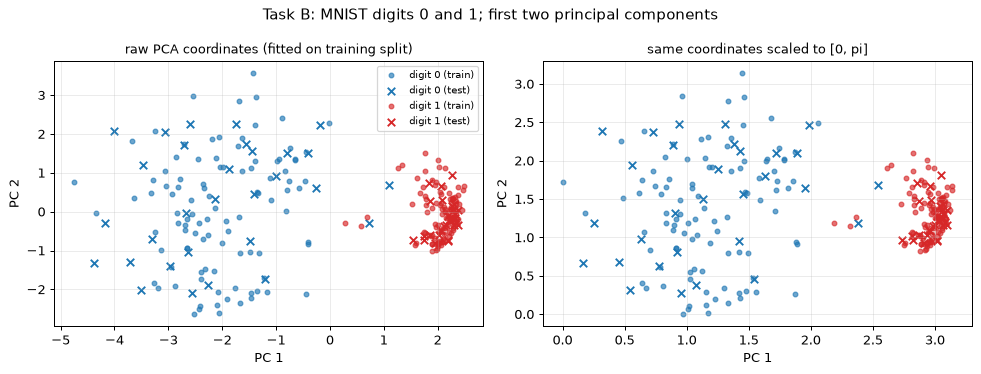

explained variance of PC1, PC2: [0.383 0.108]


In [6]:
def pca_scatter(Dtr, ytr, Dte, yte, names, title, colors=("tab:blue", "tab:red")):
    pca = PCA(n_components=2, random_state=SEED).fit(Dtr)
    Ptr, Pte = pca.transform(Dtr), pca.transform(Dte)
    ang = MinMaxScaler((0, np.pi)).fit(Ptr); Atr, Ate = ang.transform(Ptr), np.clip(ang.transform(Pte), 0, np.pi)
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, (A, B, lab) in zip(axs, ((Ptr, Pte, "raw PCA coordinates (fitted on training split)"), (Atr, Ate, "same coordinates scaled to [0, pi]"))):
        for c in (0, 1):
            ax.scatter(A[ytr == c, 0], A[ytr == c, 1], s=14, c=colors[c], alpha=0.65, label=f"{names[c]} (train)")
            ax.scatter(B[yte == c, 0], B[yte == c, 1], s=36, c=colors[c], marker="x", label=f"{names[c]} (test)")
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(lab, fontsize=10)
    axs[0].legend(fontsize=8); fig.suptitle(title); plt.tight_layout(); plt.show()
    return pca.explained_variance_ratio_


ev = pca_scatter(MED["Xtr"][:, :256].numpy(), MED["ytr"].numpy().astype(int), MED["Xte"][:, :256].numpy(), MED["yte"].numpy().astype(int),
                 ["Hand", "BreastMRI"], "Task A: real MedNIST images, first two principal components")
print("explained variance of PC1, PC2:", np.round(ev, 3))
ev = pca_scatter(MNI["Xtr"][:, :256].numpy(), MNI["ytr"].numpy().astype(int), MNI["Xte"][:, :256].numpy(), MNI["yte"].numpy().astype(int),
                 ["digit 0", "digit 1"], "Task B: MNIST digits 0 and 1; first two principal components")
print("explained variance of PC1, PC2:", np.round(ev, 3))

### Task C: the quantum data (Aubry-Andre states)

The paper prepares its quantum data on the chip: the Neel state evolves for 400 ns under the Aubry-Andre Hamiltonian (Eq. 3). Here the same
unitary $e^{-iH\tau}$ is computed **exactly** for every sample. $H$ conserves the number of excited qubits, so it is diagonalised in
the eleven particle-number sectors (the largest has 252 states) instead of the full 1024-dimensional space; the cell after the definitions
asserts agreement with `scipy.linalg.expm` of the Hamiltonian built as a Qiskit `SparsePauliOp`. Units: $g = 1$, so $g\tau = 2\pi\cdot 5\,\text{MHz}\cdot 400\,\text{ns} = 4\pi$.

In [7]:
N_Q = 10                      # ten transmon qubits in the paper
OBS_Q = 4                     # Q5 (index 4) is the read-out qubit
ALPHA = (np.sqrt(5) - 1) / 2          # incommensurate ratio of the Aubry-Andre potential V_k = V cos(2 pi alpha k + phi)
G_COUP = 1.0                          # work in units of the hopping g: g/2pi = 5 MHz
TAU = 2 * np.pi * 5e6 * 400e-9        # 400 ns of evolution, in units 1/g: g * tau = 4 pi
DIM = 2 ** N_Q
_idx = np.arange(DIM)
_bits = ((_idx[:, None] >> np.arange(N_Q)[None, :]) & 1)               # bit k of basis state i  (qubit Q_{k+1})
_pop = _bits.sum(1)
NEEL = np.zeros(DIM, dtype=complex)
NEEL[sum(1 << k for k in range(0, N_Q, 2))] = 1.0                       # CHOICE: Q1, Q3, Q5, Q7, Q9 excited (|1 0 1 0 ...>)
SECT = [np.where(_pop == m)[0] for m in range(N_Q + 1)]                 # particle-number sectors (H conserves the number of excitations)
_pos = np.zeros(DIM, dtype=int)
for s_ in SECT: _pos[s_] = np.arange(len(s_))
HOP = []                                                                 # hopping part of H inside every sector (constant)
for s_ in SECT:
    T = np.zeros((len(s_), len(s_)))
    for a, i in enumerate(s_):
        for k in range(N_Q - 1):
            if ((i >> k) & 1) != ((i >> (k + 1)) & 1):
                j = i ^ (1 << k) ^ (1 << (k + 1)); T[_pos[j], a] = -G_COUP      # -(g/2)(XX+YY) has matrix element -g between |01> and |10>
    HOP.append(T)
Z_SIGN = torch.tensor(1.0 - 2.0 * _bits, dtype=torch.float64)           # (1024, 10): <Z_k> = sum_i |psi_i|^2 Z_SIGN[i, k]


def aa_diag(V, phi):
    """On-site part  -sum_k (V_k / 2) Z_k  with V_k = V cos(2 pi alpha k + phi), k = 1..10 (V in units of g)."""
    Vk = V * np.cos(2 * np.pi * ALPHA * np.arange(1, N_Q + 1) + phi)
    return -(0.5 * Vk[None, :] * (1.0 - 2.0 * _bits)).sum(1)


def sector_unitaries(V, phi, sectors=range(N_Q + 1), tau=TAU):
    """exp(-i H tau) restricted to every particle-number sector, from an exact eigendecomposition."""
    d = aa_diag(V, phi); out = {}
    for m in sectors:
        H = HOP[m] + np.diag(d[SECT[m]])
        E, W = np.linalg.eigh(H)
        out[m] = (W * np.exp(-1j * E * tau)[None, :]) @ W.T
    return out


def stack_unitaries(Us):
    """List (one dict per sample) of sector unitaries -> dict sector -> tensor (B, d, d), so that a whole batch is evolved by 11 batched matrix products."""
    return {m: torch.tensor(np.stack([U[m] for U in Us])) for m in Us[0]}


def apply_sector_unitaries(Ust, psi):
    """psi: (B, 1024) complex tensor -> exp(-i H tau) psi for every sample (differentiable in psi)."""
    out = torch.zeros_like(psi)
    for m, U in Ust.items():
        idx = torch.tensor(SECT[m])
        out = out.index_copy(1, idx, torch.bmm(U, psi[:, idx].unsqueeze(2)).squeeze(2))
    return out

def legit_state(V, phi):
    """The quantum data point: Neel state evolved for 400 ns under the Aubry-Andre Hamiltonian (exact)."""
    U = sector_unitaries(V, phi, sectors=[N_Q // 2])[N_Q // 2]
    psi = np.zeros(DIM, dtype=complex); s_ = SECT[N_Q // 2]
    psi[s_] = U @ NEEL[s_]
    return psi


def local_z(psi):
    p = psi.real ** 2 + psi.imag ** 2
    return p @ Z_SIGN


def perturbation_product_state(psi_par, kappa):
    """Algorithm 8: U_psi = prod_k Rx(d1) Rz(d2) Rx(d3) with d_i = kappa * sin(psi_i), applied to the Neel product state. psi_par: (B, 10, 3)."""
    d = kappa * torch.sin(psi_par)
    B = d.shape[0]
    vecs = []
    for k in range(N_Q):
        bit = 1 if k % 2 == 0 else 0                                   # Neel product state: Q1, Q3, ... start in |1>
        v = torch.zeros(B, 2, dtype=torch.complex128); v[:, bit] = 1.0
        for ax, j in (("x", 0), ("z", 1), ("x", 2)):                    # gates act in the order Rx(d1) first (rightmost = first applied)
            th = d[:, k, j]; c = torch.cos(th / 2).to(torch.complex128); s = torch.sin(th / 2)
            if ax == "x":
                v = torch.stack([c * v[:, 0] - 1j * s * v[:, 1], -1j * s * v[:, 0] + c * v[:, 1]], 1)
            else:
                e = torch.exp(-0.5j * th)
                v = torch.stack([e * v[:, 0], e.conj() * v[:, 1]], 1)
        vecs.append(v)
    st = vecs[0]
    for k in range(1, N_Q):
        st = (vecs[k].unsqueeze(2) * st.unsqueeze(1)).reshape(B, -1)        # qubit k becomes the more significant bit -> little-endian index
    return st

In [8]:
# --- exactness check against the dense Hamiltonian built as a Qiskit operator ---
import scipy.linalg as sla
from qiskit.quantum_info import SparsePauliOp, Statevector


def qiskit_hamiltonian(V, phi):
    terms = []
    for k in range(N_Q - 1):
        terms += [("XX", [k, k + 1], -0.5 * G_COUP), ("YY", [k, k + 1], -0.5 * G_COUP)]
    for k in range(N_Q):
        terms.append(("Z", [k], -0.5 * V * np.cos(2 * np.pi * ALPHA * (k + 1) + phi)))
    return SparsePauliOp.from_sparse_list(terms, num_qubits=N_Q)


for V, phi in [(0.5, 1.0), (4.5, 3.0)]:
    ref = sla.expm(-1j * TAU * qiskit_hamiltonian(V, phi).to_matrix()) @ NEEL
    err = np.abs(legit_state(V, phi) - ref).max()
    assert err < 1e-10, err
    print(f"V/g = {V}: sector evolution equals expm(-i H tau)|Neel>  (max amplitude difference {err:.1e})")

V/g = 0.5: sector evolution equals expm(-i H tau)|Neel>  (max amplitude difference 2.9e-15)


V/g = 4.5: sector evolution equals expm(-i H tau)|Neel>  (max amplitude difference 8.1e-15)


In [9]:
def make_quantum_data(n_per_class, seed, cache=True):
    """Thermal (label 0): V/g ~ U[0, 1]; localized (label 1): V/g ~ U[4, 5]; phi ~ U[0, 2 pi). Returns the exact states."""
    path = os.path.join(DATA_DIR, f"aa_states_{n_per_class}_{seed}.npz")
    r = np.random.default_rng(seed)
    V = np.r_[r.uniform(0, 1, n_per_class), r.uniform(4, 5, n_per_class)]; phi = r.uniform(0, 2 * np.pi, 2 * n_per_class)
    y = np.r_[np.zeros(n_per_class), np.ones(n_per_class)]
    if cache and os.path.exists(path):
        psi = np.load(path)["psi"]
    else:
        psi = np.stack([legit_state(v, p) for v, p in zip(V, phi)])
        if cache: np.savez_compressed(path, psi=psi)
    return dict(V=V, phi=phi, y=torch.tensor(y), psi=torch.tensor(psi))


t0 = time.time()
QTR = make_quantum_data(NQ_TR_PC, SEED + 1); QTE = make_quantum_data(NQ_TE_PC, SEED + 2)
print(f"generated {len(QTR['y'])} training and {len(QTE['y'])} test states in {time.time()-t0:.0f} s")
print("state matrix (samples x basis states):", tuple(QTR["psi"].shape), "complex amplitudes; feature names: amp_|b10 ... b1> for the 1024 basis states, e.g.",
      [f"amp_{i:010b}" for i in (0, 1, 1023)])
print("original labels: thermal (V/g in [0,1]) = 0, localized (V/g in [4,5]) = 1")
for nm, Q in (("train", QTR), ("test", QTE)):
    yy = Q["y"].numpy().astype(int)
    print(f"  {nm} class counts: thermal {int((yy==0).sum())}, localized {int((yy==1).sum())}; norms 1 within {float(np.abs(np.linalg.norm(Q['psi'].numpy(), axis=1)-1).max()):.1e}")

generated 160 training and 50 test states in 0 s
state matrix (samples x basis states): (160, 1024) complex amplitudes; feature names: amp_|b10 ... b1> for the 1024 basis states, e.g. ['amp_0000000000', 'amp_0000000001', 'amp_1111111111']
original labels: thermal (V/g in [0,1]) = 0, localized (V/g in [4,5]) = 1
  train class counts: thermal 80, localized 80; norms 1 within 1.6e-15
  test class counts: thermal 25, localized 25; norms 1 within 1.2e-15


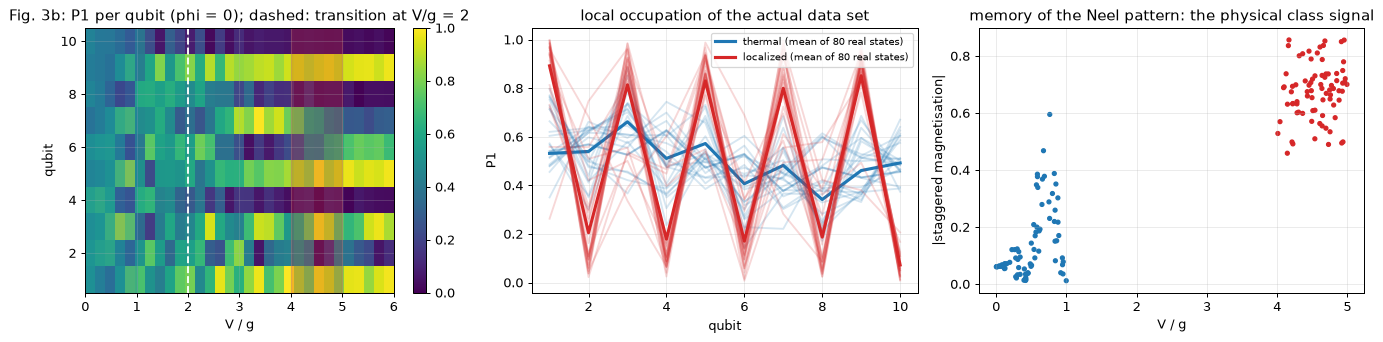

In [10]:
# Fig. 3b: occupation probability P1 of each qubit against V/g (phi = 0), and the data windows used for the two classes
grid = np.linspace(0, 6, 31)
P1 = np.array([[(1 - local_z(torch.tensor(legit_state(v, 0.0)).unsqueeze(0))[0, k].item()) / 2 for k in range(N_Q)] for v in grid])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
im = axs[0].imshow(P1.T, aspect="auto", origin="lower", extent=[0, 6, 0.5, 10.5], cmap="viridis", vmin=0, vmax=1)
axs[0].axvline(2, c="w", ls="--"); axs[0].axvspan(0, 1, color="tab:blue", alpha=0.25); axs[0].axvspan(4, 5, color="tab:red", alpha=0.25)
axs[0].set_xlabel("V / g"); axs[0].set_ylabel("qubit"); axs[0].set_title("Fig. 3b: P1 per qubit (phi = 0); dashed: transition at V/g = 2"); plt.colorbar(im, ax=axs[0])
yq = QTR["y"].numpy().astype(int)
Z_all = local_z(QTR["psi"]).numpy()
for c, col, nm in ((0, "tab:blue", "thermal"), (1, "tab:red", "localized")):
    P1_c = (1 - Z_all[yq == c]) / 2
    axs[1].plot(np.arange(1, 11), P1_c[:25].T, c=col, alpha=0.18)
    axs[1].plot(np.arange(1, 11), P1_c.mean(0), c=col, lw=2.5, label=f"{nm} (mean of {int((yq==c).sum())} real states)")
axs[1].set_xlabel("qubit"); axs[1].set_ylabel("P1"); axs[1].set_title("local occupation of the actual data set"); axs[1].legend(fontsize=8)
imb = np.array([abs(np.sum([(-1) ** k * Z_all[i, k] for k in range(N_Q)])) / N_Q for i in range(len(yq))])
axs[2].scatter(QTR["V"], imb, c=np.where(yq == 0, "tab:blue", "tab:red"), s=10)
axs[2].set_xlabel("V / g"); axs[2].set_ylabel("|staggered magnetisation|"); axs[2].set_title("memory of the Neel pattern: the physical class signal")
plt.tight_layout(); plt.show()

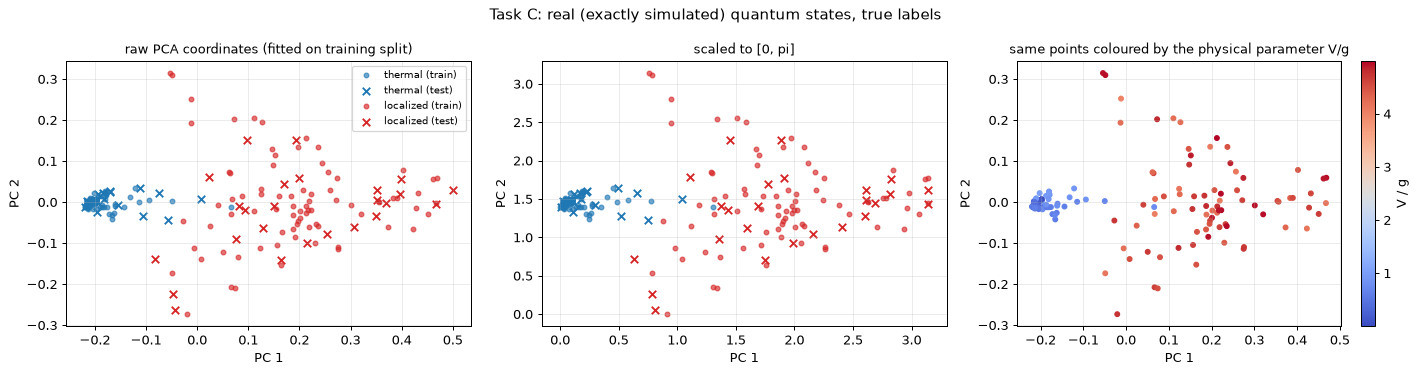

explained variance of PC1, PC2: [0.575 0.076]


In [11]:
# Labelled 2-D projection of the real quantum states: PCA of the 1024 basis-state probabilities |psi_i|^2 (phase independent), fitted on the training split.
def qstate_features(Q):
    return (Q["psi"].abs() ** 2).numpy()


pca_q = PCA(n_components=2, random_state=SEED).fit(qstate_features(QTR))
PQtr, PQte = pca_q.transform(qstate_features(QTR)), pca_q.transform(qstate_features(QTE))
angq = MinMaxScaler((0, np.pi)).fit(PQtr); AQtr, AQte = angq.transform(PQtr), np.clip(angq.transform(PQte), 0, np.pi)
yq_tr, yq_te = QTR["y"].numpy().astype(int), QTE["y"].numpy().astype(int)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (A, B, lab) in zip(axs[:2], ((PQtr, PQte, "raw PCA coordinates (fitted on training split)"), (AQtr, AQte, "scaled to [0, pi]"))):
    for c, col, nm in ((0, "tab:blue", "thermal"), (1, "tab:red", "localized")):
        ax.scatter(A[yq_tr == c, 0], A[yq_tr == c, 1], s=14, c=col, alpha=0.65, label=f"{nm} (train)")
        ax.scatter(B[yq_te == c, 0], B[yq_te == c, 1], s=36, c=col, marker="x", label=f"{nm} (test)")
    ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(lab, fontsize=10)
axs[0].legend(fontsize=8)
sc = axs[2].scatter(PQtr[:, 0], PQtr[:, 1], c=QTR["V"], cmap="coolwarm", s=14); plt.colorbar(sc, ax=axs[2], label="V / g")
axs[2].set_title("same points coloured by the physical parameter V/g", fontsize=10); axs[2].set_xlabel("PC 1"); axs[2].set_ylabel("PC 2")
fig.suptitle("Task C: real (exactly simulated) quantum states, true labels"); plt.tight_layout(); plt.show()
print("explained variance of PC1, PC2:", np.round(pca_q.explained_variance_ratio_, 3))

### Task D data (supplementary benchmark, Fig. S2-S5)

The supplementary benchmark compares two circuit layouts on MNIST and Fashion-MNIST. It uses the same 16 x 16 compression; the two classes are
digits 0 / 1 and T-shirt/top / trouser (the paper does not name the classes: **CHOICE**). They are loaded here and drawn in the figure below.

MNIST 0/1: train (120, 260) counts [60, 60], test (60, 260) counts [30, 30]; original labels 0 / 1
Fashion-MNIST T-shirt/trouser: train (120, 260) counts [60, 60], test (60, 260) counts [30, 30]; original labels 0 / 1


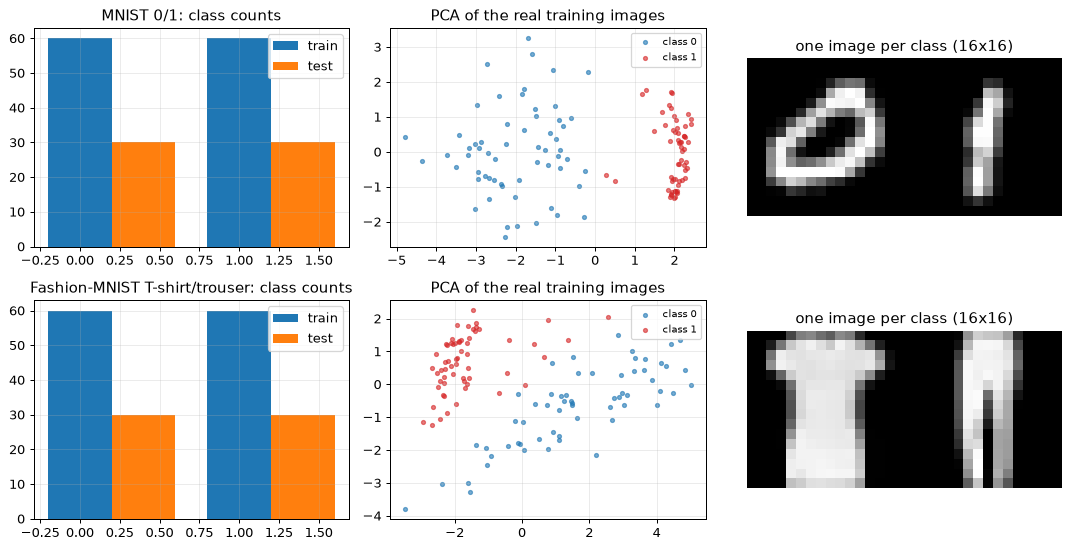

In [12]:
def abl_split(repo, seed, n_tr, n_te):
    ds = load_hf_image_dataset(repo, DATA_DIR, (0, 1), per_class_train=500, per_class_test=100, seed=SEED) if repo != "ylecun/mnist" else MN
    r = np.random.default_rng(seed); out = {}
    for name, (X, y), n in (("tr", ds["train"], n_tr), ("te", ds["test"], n_te)):
        sel = np.concatenate([r.permutation(np.where(y == c)[0])[:n // 2] for c in (0, 1)])
        out["imgs_" + name], out["y" + name], out["X" + name] = X[sel], torch.tensor(y[sel].astype(float)), to_input_vectors(X[sel])
    return out


ABL_DATA = {"MNIST 0/1": abl_split("ylecun/mnist", SEED, ABL_NTR, ABL_NTE), "Fashion-MNIST T-shirt/trouser": abl_split("zalando-datasets/fashion_mnist", SEED, ABL_NTR, ABL_NTE)}
fig, axs = plt.subplots(2, 3, figsize=(12, 6.2))
for r_, (nm, Dd) in enumerate(ABL_DATA.items()):
    cnt = [np.bincount(Dd["y" + s].numpy().astype(int), minlength=2) for s in ("tr", "te")]
    print(f"{nm}: train {tuple(Dd['Xtr'].shape)} counts {cnt[0].tolist()}, test {tuple(Dd['Xte'].shape)} counts {cnt[1].tolist()}; original labels 0 / 1")
    axs[r_, 0].bar([0, 1], cnt[0], 0.4, label="train"); axs[r_, 0].bar([0.4, 1.4], cnt[1], 0.4, label="test"); axs[r_, 0].set_title(f"{nm}: class counts"); axs[r_, 0].legend()
    pcb = PCA(2, random_state=SEED).fit(Dd["Xtr"][:, :256].numpy()); P = pcb.transform(Dd["Xtr"][:, :256].numpy()); yy = Dd["ytr"].numpy().astype(int)
    for c, col in ((0, "tab:blue"), (1, "tab:red")): axs[r_, 1].scatter(P[yy == c, 0], P[yy == c, 1], s=10, c=col, alpha=0.6, label=f"class {c}")
    axs[r_, 1].set_title("PCA of the real training images"); axs[r_, 1].legend(fontsize=8)
    ii = [np.where(yy == 0)[0][0], np.where(yy == 1)[0][0]]
    axs[r_, 2].imshow(np.concatenate([Dd["Xtr"][i, :256].reshape(16, 16).numpy() for i in ii], 1), cmap="gray"); axs[r_, 2].axis("off"); axs[r_, 2].set_title("one image per class (16x16)")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

Every number in this notebook comes from the circuits drawn in this section. Each circuit is built **twice**: once as a Qiskit
`QuantumCircuit` (the object that is drawn and that Qiskit can simulate exactly), and once as a list of gates for a fast batched PyTorch
statevector simulator that can be differentiated. A fidelity-1 test below asserts that both give the same expectation values to
10 decimals before anything is trained. No illustrative circuit is drawn.

What the paper specifies and what had to be assumed (all assumptions are `# CHOICE:` items in the code of the next cell):
- *Interleaved block encoding (Fig. 2b, Fig. S8):* 10 qubits on a chain, four blocks with 8, 6, 6 and 6 layers of one rotation per qubit,
  each block closed by two layers of CNOT gates. Rotation angle of gate $i$ = (pixel $x_i$ times `X_SCALE`) + trainable $\theta_i$. The paper shows $R_x$ and $R_z$ and
  says the gates are "selected from {Rx, Rz}": **assumed** alternating $R_x, R_z, R_x, \dots$ starting with $R_x$. CNOT layers: **assumed** pairs (Q1,Q2),(Q3,Q4),... then (Q2,Q3),(Q4,Q5),...
  with the lower qubit as control. Read-out: $\langle\sigma_z\rangle$ of Q5.
- *The paper's compilation* (each CNOT = CZ between two Hadamards, three single-qubit rotations $R_x(\pi/2)R_z(\pi/2)R_x(\pi/2)$ per Hadamard,
  neighbouring rotations merged into $R_\phi R_z$) changes the depth from the 34 of the logical circuit below to about 60 on the chip; it does not change the unitary.
- *Quantum-data classifier (Fig. S9):* 5 blocks of three rotations per qubit (**assumed** $R_x R_z R_x$) and two CNOT layers; the input is the state, there are no data gates.
- *Quantum perturbation (Algorithm 8):* one $R_x(\delta_1) R_z(\delta_2) R_x(\delta_3)$ per qubit between the Neel preparation and the (analog) Aubry-Andre evolution
  $U_{AA}$, which is a Hamiltonian evolution and not a gate sequence (it is checked against `expm` in the data section).
- *Supplementary benchmark (Fig. S1c, S2):* the 540-rotation "interleaved" and "encoding first" circuits are two distinct architectures and both are drawn.

In [13]:
import numpy as np
import torch
torch.set_num_threads(1)
N_Q = 10                      # ten transmon qubits in the paper
OBS_Q = 4                     # Q5 (0-based index 4) is the read-out qubit in the paper


class CircuitSpec:
    """A circuit = list of rotation gates + CNOT layers. Qubit q <-> bit q of the state index (Qiskit little-endian).
    ops: ('rot', axis 'x'|'z', qubit, data_index or -1, param_index or -1) or ('cx', ((control, target), ...))."""
    def __init__(self, ops, n_data, n_param, n_qubits=N_Q):
        self.ops, self.n_data, self.n_param, self.n = ops, n_data, n_param, n_qubits
        self.rot_ops = [o for o in ops if o[0] == "rot"]
        self.n_rot = len(self.rot_ops)
        self.didx = torch.tensor([o[3] if o[3] >= 0 else n_data for o in self.rot_ops])      # n_data = padding column of zeros
        self.pidx = torch.tensor([o[4] if o[4] >= 0 else n_param for o in self.rot_ops])     # n_param = padding entry of zero
        self.has_x = torch.tensor([1.0 if o[3] >= 0 else 0.0 for o in self.rot_ops], dtype=torch.float64)
        idx = np.arange(2 ** n_qubits)
        self.perms = {}
        for k, o in enumerate(ops):
            if o[0] == "cx":
                p = idx.copy()
                for c, t in o[1]:
                    p = np.where(((p >> c) & 1) == 1, p ^ (1 << t), p)      # CNOT is an involution, so the same index map works both ways
                self.perms[k] = torch.tensor(p)
        self.zsign = torch.tensor(1.0 - 2.0 * ((idx >> OBS_Q) & 1))
        # layer program for the fast simulator: every rotation layer must be ten gates of one axis on qubits 0..9 in order
        self.program, r = [], 0
        for k, o in enumerate(ops):
            if o[0] == "cx":
                self.program.append(("cx", self.perms[k], 0))
            elif o[2] == 0:
                layer = ops[k:k + n_qubits]
                assert all(g[0] == "rot" and g[1] == o[1] and g[2] == j for j, g in enumerate(layer)), "rotation layers must cover qubits 0..n-1"
                self.program.append(("rot", o[1], r)); r += n_qubits

    def n_cx(self):
        return sum(len(o[1]) for o in self.ops if o[0] == "cx")


def cx_layers(n=N_Q):
    a = tuple((q, q + 1) for q in range(0, n - 1, 2))      # (Q1,Q2), (Q3,Q4), ...
    b = tuple((q, q + 1) for q in range(1, n - 1, 2))      # (Q2,Q3), (Q4,Q5), ...
    return [("cx", a), ("cx", b)]


def medical_spec(layers_per_block=(8, 6, 6, 6), n=N_Q):
    """CHOICE: interleaved block encoding of Fig. 2b / S8: rotation angle = x + theta, alternating Rx, Rz; two CNOT layers per block."""
    ops, L = [], 0
    for nl in layers_per_block:
        for _ in range(nl):
            for q in range(n):
                ops.append(("rot", "x" if L % 2 == 0 else "z", q, L * n + q, L * n + q))
            L += 1
        ops += cx_layers(n)
    return CircuitSpec(ops, n_data=L * n, n_param=L * n)


def quantum_data_spec(n_blocks=5, n=N_Q):
    """CHOICE: 5 blocks x (Rx Rz Rx on every qubit) = 150 parameters, then two CNOT layers; no data gates (the data is the input state)."""
    ops, p = [], 0
    for _ in range(n_blocks):
        for axis in "xzx":
            for q in range(n):
                ops.append(("rot", axis, q, -1, p)); p += 1
        ops += cx_layers(n)
    return CircuitSpec(ops, n_data=0, n_param=p)


def ablation_spec(structure, n_blocks=9, n=N_Q):
    """Fig. S1b/S1c and S2: 540 rotations = 270 data angles + 270 variational angles (54 layers of ten gates), two CNOT layers after every 6 layers.
    'interleaved': every block of 6 layers = 3 data layers followed by 3 variational layers. 'encoding_first': 27 data layers first, then 27 variational layers.
    CHOICE: Rx / Rz alternate from layer to layer; the paper does not give the details of this benchmark circuit."""
    kinds = (["d"] * 3 + ["v"] * 3) * n_blocks if structure == "interleaved" else ["d"] * (3 * n_blocks) + ["v"] * (3 * n_blocks)
    ops, dl, pl = [], 0, 0
    for L, kind in enumerate(kinds):
        for q in range(n):
            ax = "x" if L % 2 == 0 else "z"
            ops.append(("rot", ax, q, dl * n + q, -1) if kind == "d" else ("rot", ax, q, -1, pl * n + q))
        dl, pl = dl + (kind == "d"), pl + (kind == "v")
        if (L + 1) % 6 == 0: ops += cx_layers(n)
    return CircuitSpec(ops, n_data=dl * n, n_param=pl * n)

_idx_all = np.arange(2 ** N_Q)
ZLO = torch.tensor(1.0 - 2.0 * ((np.arange(32)[None, :] >> np.arange(5)[:, None]) & 1))     # (5, 32): Z eigenvalues of the 5 low qubits


def _kron_layer(U, qs, cdt):
    """Kronecker product of the 2x2 gates of qubits qs (per sample) -> (B, 2^k, 2^k); qubit qs[-1] is the most significant bit."""
    K = torch.ones(U.shape[0], 1, 1, dtype=cdt)
    for q in qs:
        n = K.shape[1]
        K = torch.einsum("bxy,bij->bxiyj", U[:, q], K).reshape(U.shape[0], 2 * n, 2 * n)
    return K


def run_circuit(spec, X, theta, x_scale=1.0, state0=None, dt=None):
    """Exact statevector simulation, batched and differentiable. X: (B, n_data), theta: (n_param,). Returns <Z> of the read-out qubit, (B,).
    A layer of ten Rx gates is applied as K_hi @ S @ K_lo^T on the 32 x 32 reshaped state; a layer of Rz gates is a diagonal phase.
    dt = torch.float64 (default, used for the equivalence tests) or torch.float32 (about 2x faster, used for training and attacks)."""
    dt = dt or torch.float64
    cdt = torch.complex128 if dt == torch.float64 else torch.complex64
    B = X.shape[0]
    Xp = torch.cat([X.to(torch.float64), torch.zeros(B, 1, dtype=torch.float64)], 1)
    th = torch.cat([theta.to(torch.float64), torch.zeros(1, dtype=torch.float64)])
    ang = (x_scale * Xp[:, spec.didx] * spec.has_x + th[spec.pidx]).to(dt)
    zlo = ZLO.to(dt)
    if state0 is None:
        st = torch.zeros(B, 2 ** spec.n, dtype=cdt); st[:, 0] = 1.0
    else:
        st = state0.to(cdt)
        if st.dim() == 1: st = st.unsqueeze(0).expand(B, -1)
    for kind, payload, r in spec.program:
        if kind == "cx":
            st = st[:, payload]
            continue
        a = ang[:, r:r + spec.n]
        if payload == "x":
            c = torch.cos(a / 2).to(cdt); s = -1j * torch.sin(a / 2)
            U = torch.stack([torch.stack([c, s], 2), torch.stack([s, c], 2)], 2)             # (B, 10, 2, 2)
            Klo, Khi = _kron_layer(U, range(0, 5), cdt), _kron_layer(U, range(5, 10), cdt)
            st = torch.bmm(torch.bmm(Khi, st.reshape(B, 32, 32)), Klo.transpose(1, 2)).reshape(B, -1)
        else:
            plo = torch.exp(-0.5j * (a[:, :5] @ zlo)); phi = torch.exp(-0.5j * (a[:, 5:] @ zlo))
            st = (st.reshape(B, 32, 32) * phi.unsqueeze(2) * plo.unsqueeze(1)).reshape(B, -1)
    return ((st.real ** 2 + st.imag ** 2) * spec.zsign.to(dt)).sum(1)


def run_circuit_gatewise(spec, X, theta, x_scale=1.0, state0=None):
    """Slow reference: one gate at a time (float64). Used only to test the fast layer-wise simulator."""
    B = X.shape[0]
    Xp = torch.cat([X, torch.zeros(B, 1, dtype=X.dtype)], 1)
    th = torch.cat([theta, torch.zeros(1, dtype=theta.dtype)])
    ang = x_scale * Xp[:, spec.didx] * spec.has_x + th[spec.pidx]
    C, S, E = torch.cos(ang / 2), torch.sin(ang / 2), torch.exp(-0.5j * ang)
    dim = 2 ** spec.n
    if state0 is None:
        st = torch.zeros(B, dim, dtype=torch.complex128); st[:, 0] = 1.0
    else:
        st = state0.to(torch.complex128)
        if st.dim() == 1: st = st.unsqueeze(0).expand(B, -1)
    r = 0
    for k, o in enumerate(spec.ops):
        if o[0] == "cx":
            st = st[:, spec.perms[k]]; continue
        _, axis, q, _, _ = o
        v = st.reshape(B, dim >> (q + 1), 2, 1 << q)
        if axis == "x":
            c = C[:, r].reshape(B, 1, 1).to(torch.complex128); s = (-1j * S[:, r]).reshape(B, 1, 1)
            v = torch.stack([c * v[:, :, 0] + s * v[:, :, 1], s * v[:, :, 0] + c * v[:, :, 1]], 2)
        else:
            e = E[:, r].reshape(B, 1, 1)
            v = torch.stack([e * v[:, :, 0], e.conj() * v[:, :, 1]], 2)
        st = v.reshape(B, dim); r += 1
    return ((st.real ** 2 + st.imag ** 2) * spec.zsign).sum(1)


from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp


def to_qiskit(spec, name="a"):
    """The circuit of a CircuitSpec as a real Qiskit circuit. Every rotation gets its own symbolic angle a[i] = x_scale * x[d(i)] + theta[p(i)]."""
    a = ParameterVector(name, spec.n_rot)
    qc = QuantumCircuit(spec.n)
    r = 0
    for o in spec.ops:
        if o[0] == "rot":
            (qc.rx if o[1] == "x" else qc.rz)(a[r], o[2]); r += 1
        else:
            for c, t in o[1]:
                qc.cx(c, t)
            qc.barrier()
    return qc, a


def rotation_angles(spec, x, theta, x_scale):
    """Numeric angle of every rotation gate, in circuit order (numpy)."""
    xp = np.concatenate([np.asarray(x, float), [0.0]]); tp = np.concatenate([np.asarray(theta, float), [0.0]])
    return x_scale * xp[spec.didx.numpy()] * spec.has_x.numpy() + tp[spec.pidx.numpy()]


Z_READOUT = SparsePauliOp.from_sparse_list([("Z", [OBS_Q], 1.0)], num_qubits=N_Q)


def qiskit_expz(spec, qc, params, x, theta, x_scale, state0=None):
    bound = qc.assign_parameters(dict(zip(params, rotation_angles(spec, x, theta, x_scale))))
    sv = Statevector.from_int(0, 2 ** spec.n) if state0 is None else Statevector(np.asarray(state0))
    return float(np.real(sv.evolve(bound).expectation_value(Z_READOUT)))

In [14]:
SPEC_MED = medical_spec()                          # tasks A and B (MNIST uses the same circuit, only 50 of the 260 parameters are trained)
SPEC_Q = quantum_data_spec()                       # task C classifier
SPEC_INT, SPEC_EF = ablation_spec("interleaved"), ablation_spec("encoding_first")      # task D
QC = {name: to_qiskit(spec) for name, spec in (("A/B image classifier (interleaved, 4 blocks)", SPEC_MED), ("C quantum-state classifier (5 blocks)", SPEC_Q),
                                                ("D interleaved (9 blocks)", SPEC_INT), ("D encoding first", SPEC_EF))}
rows = []
for (name, (qc, par)), spec in zip(QC.items(), (SPEC_MED, SPEC_Q, SPEC_INT, SPEC_EF)):
    rows.append(dict(architecture=name, qubits=qc.num_qubits, depth=qc.depth(), rotation_gates=spec.n_rot, CNOT_gates=spec.n_cx(),
                     trainable_parameters=spec.n_param, data_angles=int((spec.has_x > 0).sum()), readout="Z of Q5"))
display(pd.DataFrame(rows))

,architecture,qubits,depth,rotation_gates,CNOT_gates,trainable_parameters,data_angles,readout
0,"A/B image classifier (interleaved, 4 blocks)",10,34,260,36,260,260,Z of Q5
1,C quantum-state classifier (5 blocks),10,25,150,45,150,0,Z of Q5
2,D interleaved (9 blocks),10,72,540,81,270,270,Z of Q5
3,D encoding first,10,72,540,81,270,270,Z of Q5


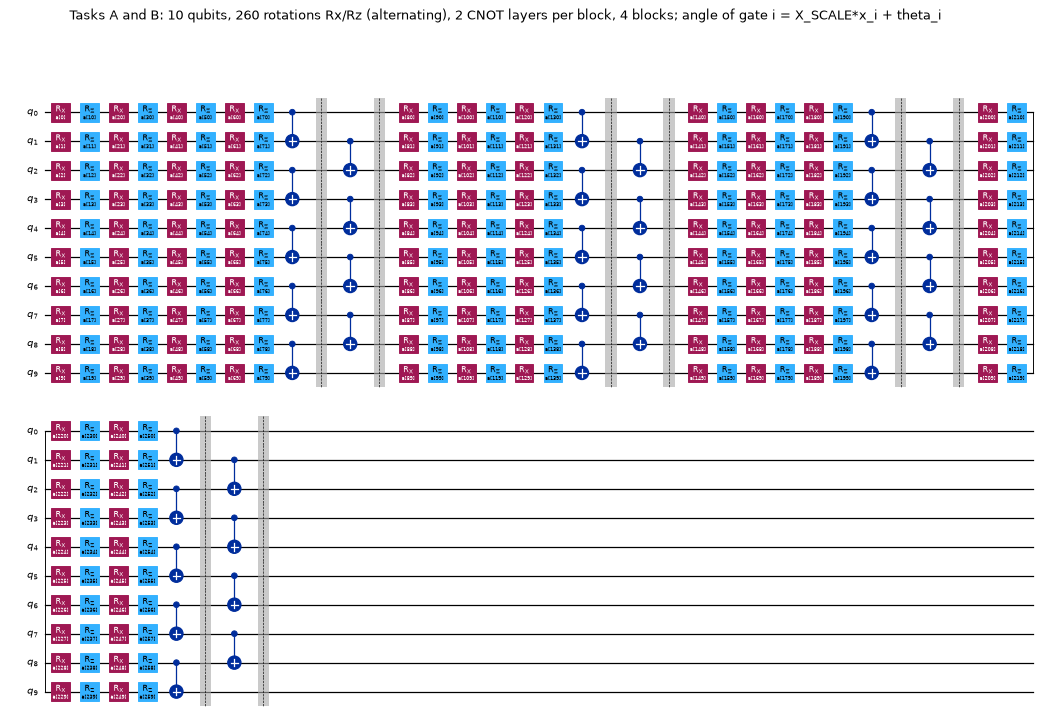

qubits 10 | depth 34 (paper: about 60 after compilation to CZ + Rphi/Rz) | rotations 260 | CNOT 36 | trainable parameters 260
gate counts: {'rx': 130, 'rz': 130, 'cx': 36, 'barrier': 8}


In [15]:
# Fig. 2b / S8: the circuit that is actually executed for tasks A and B. Every rotation shows its symbolic angle a[i] = X_SCALE * x[i] + theta[i].
qc_med, par_med = QC["A/B image classifier (interleaved, 4 blocks)"]
fig = qc_med.draw("mpl", fold=34, scale=0.5, idle_wires=True)
fig.suptitle("Tasks A and B: 10 qubits, 260 rotations Rx/Rz (alternating), 2 CNOT layers per block, 4 blocks; angle of gate i = X_SCALE*x_i + theta_i", fontsize=10)
display(fig); plt.close(fig)
print(f"qubits {qc_med.num_qubits} | depth {qc_med.depth()} (paper: about 60 after compilation to CZ + Rphi/Rz) | rotations {SPEC_MED.n_rot} | CNOT {SPEC_MED.n_cx()} | trainable parameters {SPEC_MED.n_param}")
print("gate counts:", dict(qc_med.count_ops()))

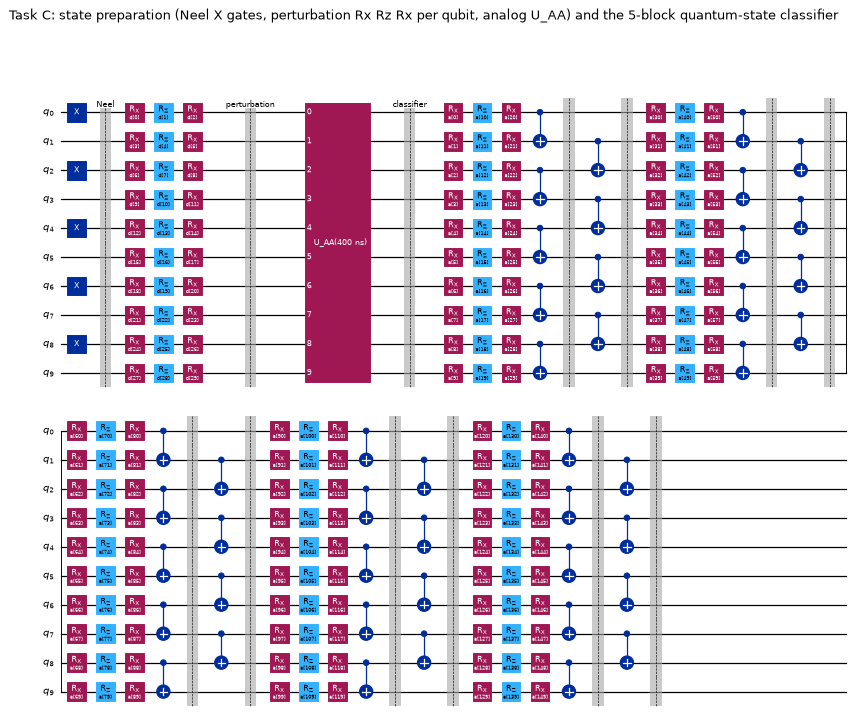

classifier: qubits 10 | depth 25 | rotations 150 | CNOT 45 | trainable parameters 150
full pipeline: depth 30 | perturbation parameters 30 (bounded by 0.5 through kappa*sin(psi))


In [16]:
# Fig. S9 + Algorithm 8: Neel preparation, local perturbation layer, analog Aubry-Andre evolution (opaque gate), then the 5-block classifier. This is task C.
from qiskit.circuit import Gate
qc_cls, par_cls = QC["C quantum-state classifier (5 blocks)"]
psi_par = ParameterVector("d", 3 * N_Q)
qc_full = QuantumCircuit(N_Q)
for k in range(0, N_Q, 2): qc_full.x(k)                                   # Neel state |1010101010>
qc_full.barrier(label="Neel")
for k in range(N_Q):                                                      # perturbation layer (identity when all d = 0)
    qc_full.rx(psi_par[3 * k], k); qc_full.rz(psi_par[3 * k + 1], k); qc_full.rx(psi_par[3 * k + 2], k)
qc_full.barrier(label="perturbation")
qc_full.append(Gate("U_AA(400 ns)", N_Q, []), list(range(N_Q)))          # analog evolution under the Aubry-Andre Hamiltonian (exact, see data section)
qc_full.barrier(label="classifier")
qc_full = qc_full.compose(qc_cls)
fig = qc_full.draw("mpl", fold=27, scale=0.5, idle_wires=True)
fig.suptitle("Task C: state preparation (Neel X gates, perturbation Rx Rz Rx per qubit, analog U_AA) and the 5-block quantum-state classifier", fontsize=10)
display(fig); plt.close(fig)
print(f"classifier: qubits {qc_cls.num_qubits} | depth {qc_cls.depth()} | rotations {SPEC_Q.n_rot} | CNOT {SPEC_Q.n_cx()} | trainable parameters {SPEC_Q.n_param}")
print(f"full pipeline: depth {qc_full.depth()} | perturbation parameters {len(psi_par)} (bounded by {KAPPA} through kappa*sin(psi))")

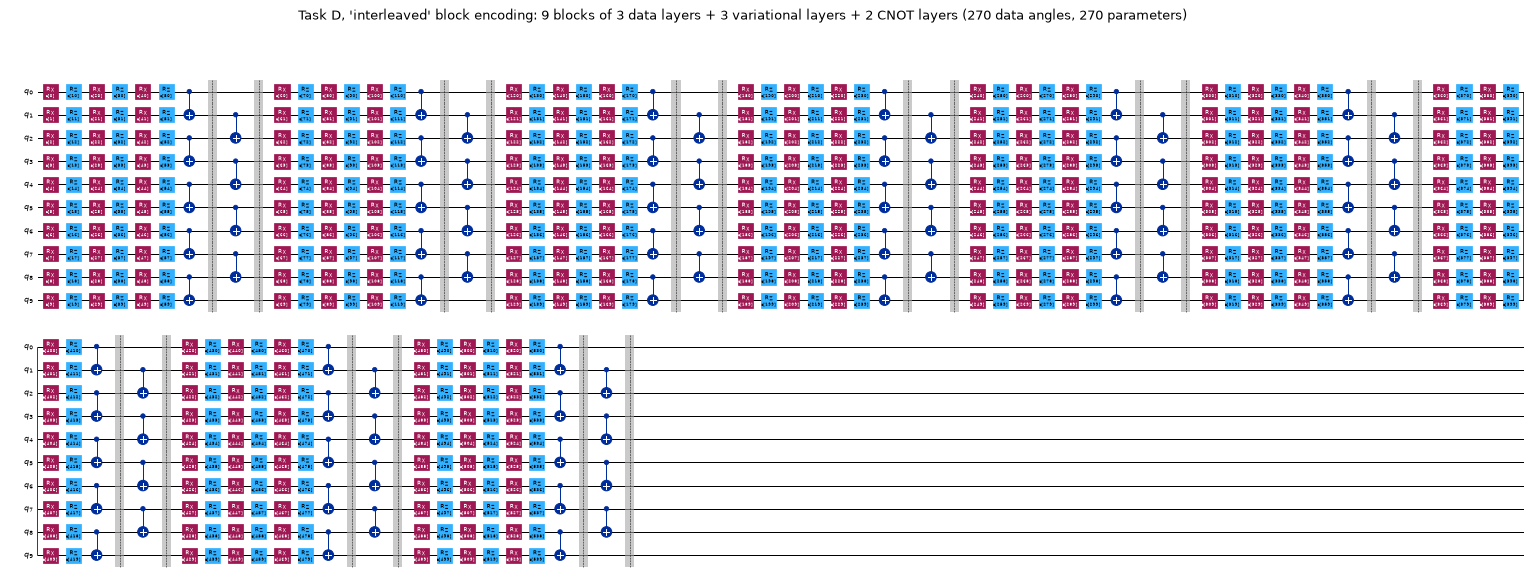

D interleaved (9 blocks) | qubits 10 | depth 72 | rotations 540 | CNOT 81


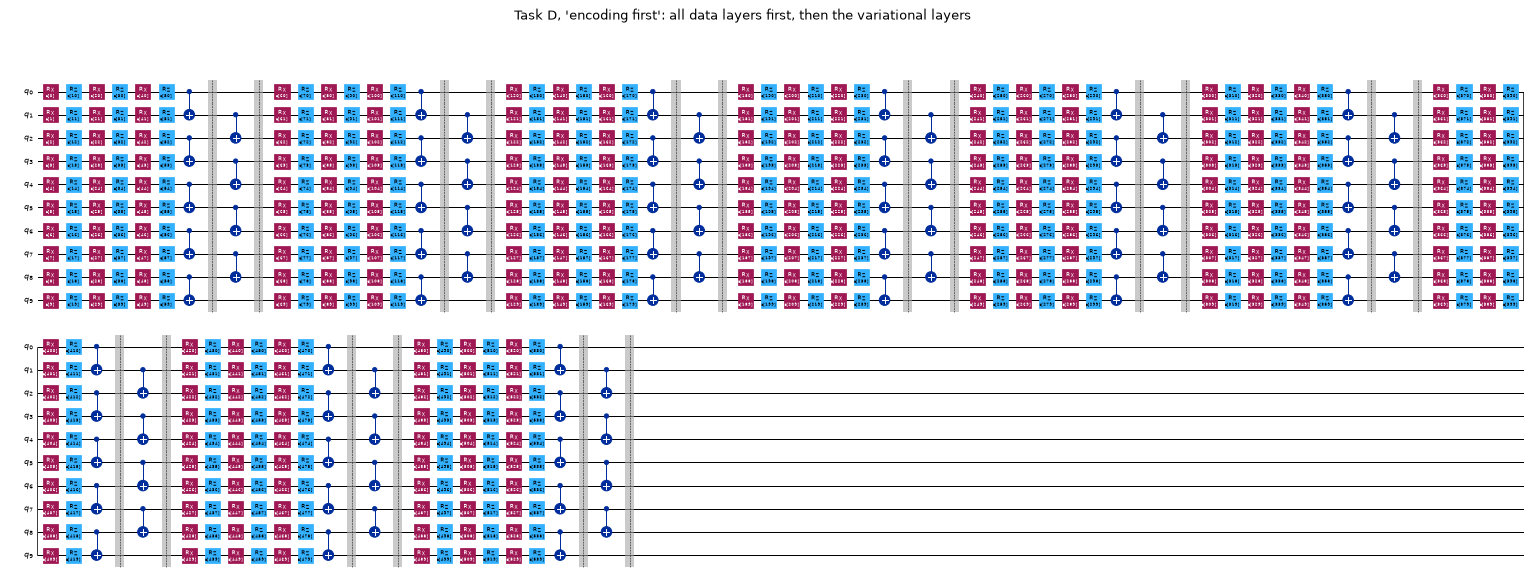

D encoding first | qubits 10 | depth 72 | rotations 540 | CNOT 81


In [17]:
# Task D: the two distinct 540-rotation architectures of Fig. S1c (interleaved) and S1b (encoding first).
for title, key in (("Task D, 'interleaved' block encoding: 9 blocks of 3 data layers + 3 variational layers + 2 CNOT layers (270 data angles, 270 parameters)", "D interleaved (9 blocks)"),
                   ("Task D, 'encoding first': all data layers first, then the variational layers", "D encoding first")):
    qcx, parx = QC[key]
    fig = qcx.draw("mpl", fold=64, scale=0.4, idle_wires=True); fig.suptitle(title, fontsize=10); display(fig); plt.close(fig)
    print(key, "| qubits", qcx.num_qubits, "| depth", qcx.depth(), "| rotations", len(parx), "| CNOT", qcx.count_ops().get("cx", 0))

### Fidelity-1 test of the simulator, and the parameter-shift rule

Three computations of $\langle Z_5\rangle$ must agree: the batched PyTorch simulator in double precision, the same simulator in single precision (used
for training because it is about twice as fast), a slow gate-by-gate simulator, and Qiskit's `Statevector` of the circuit drawn above. The last cell checks
that the autograd gradient (used for training and attacks) equals the **parameter-shift rule** $\partial\langle B\rangle/\partial\theta = (\langle B\rangle_{\theta+\pi/2}-\langle B\rangle_{\theta-\pi/2})/2$
that the experiment uses, evaluated with Qiskit.

In [18]:
r_ = np.random.default_rng(SEED)
rows = []
for name, spec, xs in (("A/B", SPEC_MED, 1.0), ("C", SPEC_Q, 1.0), ("D interleaved", SPEC_INT, 1.0), ("D encoding first", SPEC_EF, 1.0)):
    qc, par = QC[{"A/B": "A/B image classifier (interleaved, 4 blocks)", "C": "C quantum-state classifier (5 blocks)", "D interleaved": "D interleaved (9 blocks)",
                  "D encoding first": "D encoding first"}[name]]
    X = torch.tensor(r_.random((4, spec.n_data))); th = torch.tensor(r_.uniform(0, 2 * np.pi, spec.n_param))
    st0 = None
    if name == "C":
        s_ = r_.normal(size=(4, 2 ** N_Q)) + 1j * r_.normal(size=(4, 2 ** N_Q)); st0 = torch.tensor(s_ / np.linalg.norm(s_, axis=1, keepdims=True))
    z64 = run_circuit(spec, X, th, xs, state0=st0).numpy()
    z32 = run_circuit(spec, X, th, xs, state0=st0, dt=torch.float32).numpy()
    zgw = run_circuit_gatewise(spec, X, th, xs, state0=st0).numpy()
    zq = np.array([qiskit_expz(spec, qc, par, X[i].numpy(), th.numpy(), xs, None if st0 is None else st0[i].numpy()) for i in range(4)])
    e64, e32, egw = np.abs(z64 - zq).max(), np.abs(z32 - zq).max(), np.abs(zgw - zq).max()
    assert e64 < 1e-10 and egw < 1e-10 and e32 < 1e-5, (name, e64, e32, egw)
    rows.append(dict(circuit=name, max_err_float64=e64, max_err_float32=e32, max_err_gatewise=egw))
display(pd.DataFrame(rows).assign(**{c: [f"{v:.1e}" for v in pd.DataFrame(rows)[c]] for c in ["max_err_float64", "max_err_float32", "max_err_gatewise"]}))
print("EQUIVALENCE ASSERTED: fast simulator == gate-by-gate simulator == Qiskit Statevector")

# the perturbation layer: product state of the drawn Qiskit circuit equals the one used in the attack
pp = torch.tensor(r_.normal(size=(1, N_Q, 3)))
mine = perturbation_product_state(pp, KAPPA)[0].numpy()
qc_p = QuantumCircuit(N_Q)
for k in range(0, N_Q, 2): qc_p.x(k)
dd = KAPPA * np.sin(pp[0].numpy())
for k in range(N_Q): qc_p.rx(dd[k, 0], k); qc_p.rz(dd[k, 1], k); qc_p.rx(dd[k, 2], k)
assert np.abs(Statevector(qc_p).data - mine).max() < 1e-12
print("PERTURBATION LAYER ASSERTED: kappa*sin(psi) Rx Rz Rx on the Neel state equals the Qiskit circuit")

# parameter-shift rule with Qiskit versus autograd
X1 = torch.tensor(r_.random((1, SPEC_MED.n_data))); th1 = torch.tensor(r_.uniform(0, 2 * np.pi, SPEC_MED.n_param), requires_grad=True)
run_circuit(SPEC_MED, X1, th1, 1.0).sum().backward()
errs = []
for j in r_.choice(SPEC_MED.n_param, 6, replace=False):
    tp, tm = th1.detach().numpy().copy(), th1.detach().numpy().copy(); tp[j] += np.pi / 2; tm[j] -= np.pi / 2
    ps = 0.5 * (qiskit_expz(SPEC_MED, qc_med, par_med, X1[0].numpy(), tp, 1.0) - qiskit_expz(SPEC_MED, qc_med, par_med, X1[0].numpy(), tm, 1.0))
    errs.append(abs(ps - th1.grad[j].item()))
assert max(errs) < 1e-9, errs
print(f"PARAMETER SHIFT ASSERTED: Qiskit parameter-shift gradient == autograd gradient (max difference {max(errs):.1e} over 6 random parameters)")

,circuit,max_err_float64,max_err_float32,max_err_gatewise
0,A/B,3.3e-16,2.5e-07,2.5e-16
1,C,1.1e-16,2.8e-08,3.8e-17
2,D interleaved,3.5e-16,5.0e-08,3.8e-17
3,D encoding first,1.6e-16,1.7e-07,1.2e-16


EQUIVALENCE ASSERTED: fast simulator == gate-by-gate simulator == Qiskit Statevector
PERTURBATION LAYER ASSERTED: kappa*sin(psi) Rx Rz Rx on the Neel state equals the Qiskit circuit


PARAMETER SHIFT ASSERTED: Qiskit parameter-shift gradient == autograd gradient (max difference 2.6e-16 over 6 random parameters)


## Training, attacks, defences and baselines: the tools

The cells below define everything the three experiments reuse. They contain no results.

**Training (Algorithms 1, 2, 5, 6, 7).** `train_group_wise` splits the parameters into groups. In every epoch each group in turn takes one Adam step on the mean gradient of
a fresh random mini-batch. Gradients are exact; on the chip the paper estimates the same numbers with the parameter-shift rule (tested above).

**White-box attack (Eq. 2, Algorithms 3, 4 and 8).** Adam gradient *ascent* on the cross entropy with respect to the input. The paper restricts the perturbation to "a small region" without
giving a size. Here the region is an $\ell_\infty$ ball of radius $\varepsilon$ in pixel units (grey range 0 to 1), which is the standard way to make a budget explicit and lets us run **the same attack with the same budget on classical models**. Type-1 perturbs every pixel, type-2 only the pixels of the object
(intensity above 0.1). The attack keeps the strongest iterate of every sample.

**Checking that a failed attack is not gradient masking.** A defence can look robust only because its gradients are uninformative (flat, noisy, shattered). Three controls are run:
1. *Attack ladder:* one-step FGSM, the multi-step attack, the multi-step attack with random restarts, and **SPSA**, an attack that never looks at a gradient. A real robustness gain keeps accuracy high under all of them;
   masking shows up as the gradient-free attack being clearly stronger than the gradient attacks.
2. *Budget sweep:* accuracy must fall monotonically with $\varepsilon$ and reach about zero for large $\varepsilon$.
3. *Adaptive evaluation of the defence:* the adversarially retrained model is attacked afresh (white box, against its own parameters); the paper only evaluates it on examples that were made against the *original* model.

**Classical baselines on identical inputs.** Logistic regression, an RBF-kernel SVM and a 256-32-1 MLP see the same 256 pixels as the circuit and are attacked with the same $\varepsilon$ and the same procedure
(for the SVM the decision function is rewritten in PyTorch so that it can be differentiated). The MLP is also adversarially retrained with the paper's recipe.

In [19]:
SIM_DT = torch.float32            # CHOICE: single precision inside training / attacks (about 2x faster); equivalence tests use float64


class GroupAdam:
    """Adam with its own first/second-moment state per parameter, updated only for the parameters of the group being trained."""
    def __init__(self, n, lr, b1=0.9, b2=0.999, eps=1e-8):
        self.m = np.zeros(n); self.v = np.zeros(n); self.t = np.zeros(n); self.lr, self.b1, self.b2, self.eps = lr, b1, b2, eps

    def step(self, theta, grad, idx):
        self.t[idx] += 1
        self.m[idx] = self.b1 * self.m[idx] + (1 - self.b1) * grad[idx]
        self.v[idx] = self.b2 * self.v[idx] + (1 - self.b2) * grad[idx] ** 2
        mh = self.m[idx] / (1 - self.b1 ** self.t[idx]); vh = self.v[idx] / (1 - self.b2 ** self.t[idx])
        theta[idx] -= self.lr * mh / (np.sqrt(vh) + self.eps)
        return theta


def ce_loss_from_z(z, y):
    """Eq. 1 for two classes: g_0 = (1 + <Z>)/2 (class 0 when <Z> >= 0), g_1 = (1 - <Z>)/2, loss = -log g_y."""
    g = torch.stack([(1 + z) / 2, (1 - z) / 2], 1).clamp_min(1e-9)
    return -torch.log(g.gather(1, y.long().view(-1, 1))).view(-1)


def predict_class(z):
    return (z < 0).long()


def make_forward(spec, x_scale):
    """Forward function X, theta -> <Z_readout> (float64) for classical inputs encoded in the rotation angles."""
    return lambda X, th: run_circuit(spec, X, th, x_scale, dt=SIM_DT).double()


def make_state_forward(spec):
    """Forward function for quantum data: the input rows are state vectors that the circuit acts on."""
    return lambda P, th: run_circuit(spec, torch.zeros(len(P), 0, dtype=torch.float64), th, 1.0, state0=P, dt=SIM_DT).double()


def eval_z(fwd, X, theta_np, chunk=250):
    with torch.no_grad():
        th = torch.tensor(theta_np)
        return torch.cat([fwd(X[i:i + chunk], th) for i in range(0, len(X), chunk)])


def acc_of(fwd, X, y, theta_np):
    return float((predict_class(eval_z(fwd, X, theta_np)) == y.long()).double().mean())


def train_group_wise(fwd, n_param, Xtr, ytr, Xte, yte, lr, epochs, groups, batch, seed, theta0=None, init_std=None, eval_n=200,
                     extra_eval=None, batch_fn=None, record_every=1):
    """Paper's Algorithms 1, 2, 5, 6, 7: the parameters are split into groups (one per qubit row, or a single group of 50); in every epoch each
    group in turn gets one Adam step from the mean gradient of a random mini-batch. The gradient is exact (autograd), i.e. what the
    parameter-shift rule measures on a device. extra_eval: dict name -> (X, y) evaluated at every epoch next to the test set.
    batch_fn(rng) -> index array overrides the default random mini-batch (used for the 10 legitimate + 10 adversarial adversarial-training batch)."""
    rng = np.random.default_rng(seed)
    if theta0 is not None:
        theta = theta0.copy()
    elif init_std is None:
        theta = rng.uniform(0, 2 * np.pi, n_param)
    else:
        theta = rng.normal(0, init_std, n_param)
    opt = GroupAdam(n_param, lr)
    ev_idx = np.sort(rng.choice(len(ytr), size=min(eval_n, len(ytr)), replace=False))       # fixed subset of the training set for the per-epoch curve
    hist = {"epoch": [], "train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for k in (extra_eval or {}): hist["acc_" + k] = []
    snapshots = {}

    def record(ep):
        ztr, zte = eval_z(fwd, Xtr[ev_idx], theta), eval_z(fwd, Xte, theta)
        hist["epoch"].append(ep)
        hist["train_loss"].append(float(ce_loss_from_z(ztr, ytr[ev_idx]).mean())); hist["test_loss"].append(float(ce_loss_from_z(zte, yte).mean()))
        hist["train_acc"].append(float((predict_class(ztr) == ytr[ev_idx].long()).double().mean()))
        hist["test_acc"].append(float((predict_class(zte) == yte.long()).double().mean()))
        for k, (Xe, ye) in (extra_eval or {}).items():
            hist["acc_" + k].append(acc_of(fwd, Xe, ye, theta))
        snapshots[ep] = zte.numpy().copy()

    record(0)
    for ep in range(1, epochs + 1):
        for g in groups:
            b = rng.choice(len(ytr), size=batch, replace=False) if batch_fn is None else batch_fn(rng)
            th = torch.tensor(theta, requires_grad=True)
            ce_loss_from_z(fwd(Xtr[b], th), ytr[b]).mean().backward()
            theta = opt.step(theta, th.grad.numpy(), g)
        if ep % record_every == 0 or ep == epochs: record(ep)
    return theta, hist, snapshots


def pgd_attack(loss_fn, X, y, eps, steps, lr, mask=None, lo=0.0, hi=1.0, restarts=1, seed=0, free_cols=None):
    """Untargeted white-box attack = Eq. 2 / Algorithms 3-4: Adam gradient ASCENT on the cross-entropy w.r.t. the input.
    CHOICE: the 'small region Delta' is an l_inf ball of radius eps around the legitimate sample (pixel scale [0, 1]) intersected with the valid pixel range.
    mask (0/1 per input element) restricts the perturbation: all ones = type-1 example, object-area mask = type-2 example.
    With restarts > 1 the strongest example over random starts is kept (adaptive: more restarts = stronger attack)."""
    g = torch.Generator().manual_seed(seed)
    m = torch.ones(X.shape[1], dtype=X.dtype) if mask is None else mask.to(X.dtype)
    if m.dim() == 1: m = m.unsqueeze(0)
    best_X, best_loss = X.clone(), torch.full((X.shape[0],), -1e9, dtype=X.dtype)
    for r in range(restarts):
        delta = torch.zeros_like(X) if r == 0 else (torch.rand(X.shape, generator=g, dtype=X.dtype) * 2 - 1) * eps * m
        delta = torch.clamp(X + delta, lo, hi) - X                      # random starts must also be valid pixel values
        if free_cols is not None: delta[:, free_cols] = 0
        delta.requires_grad_(True)
        opt = torch.optim.Adam([delta], lr=lr, maximize=True)
        for t in range(steps + 1):
            xa = X + delta
            L = loss_fn(xa, y)
            with torch.no_grad():
                better = L.detach() > best_loss
                best_loss = torch.where(better, L.detach(), best_loss)
                best_X[better] = xa.detach()[better]
            if t == steps: break
            opt.zero_grad(); L.sum().backward(); opt.step()
            with torch.no_grad():
                delta.copy_(torch.clamp(delta * m, -eps, eps))
                delta.copy_(torch.clamp(X + delta, lo, hi) - X)
                if free_cols is not None: delta[:, free_cols] = 0
    return best_X.detach()


import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


class ClassicalModel:
    """A classical classifier with a differentiable logit f(x) for class 1 (so the very same white-box attack can be run on it)."""
    def __init__(self, name, logit_fn, n_feat):
        self.name, self.logit, self.n_feat = name, logit_fn, n_feat

    def z(self, X):
        return self.logit(X[:, :self.n_feat])

    def predict(self, X):
        with torch.no_grad():
            return (self.z(X) > 0).long()

    def acc(self, X, y):
        return float((self.predict(X) == y.long()).double().mean())

    def loss_fn(self):
        return lambda xa, y: F.softplus(-(2 * y.double() - 1) * self.z(xa))          # binary cross entropy of the logit


def fit_logreg(X, y, n_feat, seed):
    clf = LogisticRegression(C=1.0, max_iter=2000, random_state=seed).fit(X[:, :n_feat].numpy(), y.numpy())
    w, b = torch.tensor(clf.coef_[0]), float(clf.intercept_[0])
    return ClassicalModel("logistic regression", lambda x: x @ w + b, n_feat)


def fit_svm_rbf(X, y, n_feat, seed):
    clf = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed).fit(X[:, :n_feat].numpy(), y.numpy())
    sv, dc, b, gam = torch.tensor(clf.support_vectors_), torch.tensor(clf.dual_coef_[0]), float(clf.intercept_[0]), float(clf._gamma)
    return ClassicalModel("RBF SVM", lambda x: torch.exp(-gam * torch.cdist(x, sv) ** 2) @ dc + b, n_feat)


def fit_mlp(X, y, n_feat, seed, hidden=32, epochs=300, lr=0.01):
    """Small dense network n_feat -> 32 (ReLU) -> 1, full-batch Adam. Also used for the adversarially retrained baseline (X, y then contain adversarial rows)."""
    g = torch.Generator().manual_seed(seed)
    W1 = (torch.randn(n_feat, hidden, generator=g, dtype=torch.float64) / np.sqrt(n_feat)).requires_grad_(True)
    b1 = torch.zeros(hidden, dtype=torch.float64, requires_grad=True)
    W2 = (torch.randn(hidden, 1, generator=g, dtype=torch.float64) / np.sqrt(hidden)).requires_grad_(True)
    b2 = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.Adam([W1, b1, W2, b2], lr=lr)
    Xf, yf = X[:, :n_feat], y.double()
    for _ in range(epochs):
        opt.zero_grad()
        z = (torch.relu(Xf @ W1 + b1) @ W2 + b2).squeeze(1)
        F.binary_cross_entropy_with_logits(z, yf).backward(); opt.step()
    W1, b1, W2, b2 = (t.detach() for t in (W1, b1, W2, b2))
    return ClassicalModel("MLP 256-32-1", lambda x: (torch.relu(x @ W1 + b1) @ W2 + b2).squeeze(1), n_feat)


def spsa_attack(loss_fn, X, y, eps, iters, lr, mask=None, lo=0.0, hi=1.0, seed=0, free_cols=None):
    """Gradient-FREE attack (SPSA, needs only loss evaluations): a sanity check against gradient masking. If this beats the gradient attack,
    the gradient attack is being fooled. Keeps the best (highest-loss) iterate per sample."""
    g = torch.Generator().manual_seed(seed)
    m = torch.ones(X.shape[1], dtype=X.dtype) if mask is None else mask.to(X.dtype)
    if m.dim() == 1: m = m.unsqueeze(0)
    delta = torch.zeros_like(X)
    with torch.no_grad():
        best_loss = loss_fn(X, y).clone(); best_X = X.clone()
        for t in range(iters):
            s = (torch.randint(0, 2, X.shape, generator=g).double() * 2 - 1) * m
            c = max(eps / 2, 1e-3)
            Lp = loss_fn(torch.clamp(X + torch.clamp(delta + c * s, -eps, eps), lo, hi), y)
            Lm = loss_fn(torch.clamp(X + torch.clamp(delta - c * s, -eps, eps), lo, hi), y)
            ghat = ((Lp - Lm) / (2 * c)).unsqueeze(1) * s
            delta = torch.clamp(delta + lr * torch.sign(ghat) * m, -eps, eps)
            if free_cols is not None: delta[:, free_cols] = 0
            xa = torch.clamp(X + delta, lo, hi)
            L = loss_fn(xa, y)
            better = L > best_loss
            best_loss = torch.where(better, L, best_loss); best_X[better] = xa[better]
    return best_X

In [20]:
PAD = torch.arange(256, 260)           # the four zero-padding inputs are never perturbed


def object_mask(X, thr=0.1):
    """Type-2 mask: 1 where the object is (pixel intensity above thr in the legitimate image), 0 elsewhere and on the padding."""
    m = (X > thr).double(); m[:, 256:] = 0
    return m


class QModel:
    """The trained quantum classifier seen as a model: z = <sigma_z> of Q5, class 0 if z >= 0. Same interface as ClassicalModel."""
    def __init__(self, spec, x_scale, theta, name="quantum circuit (10 qubits)"):
        self.name, self.spec, self.x_scale, self.theta = name, spec, x_scale, np.asarray(theta).copy()
        self.fwd = make_forward(spec, x_scale)

    def z(self, X):
        return self.fwd(X, torch.tensor(self.theta))

    def predict(self, X):
        with torch.no_grad():
            return torch.cat([(self.z(X[i:i + 250]) < 0).long() for i in range(0, len(X), 250)])

    def acc(self, X, y):
        return float((self.predict(X) == y.long()).double().mean())

    def loss_fn(self):
        th = torch.tensor(self.theta)
        return lambda xa, y: ce_loss_from_z(self.fwd(xa, th), y)


def run_attack(model, X, y, eps, steps=None, mask=None, restarts=1, seed=0, chunk=100, kind="pgd", spsa_iters=None):
    """White-box (kind='pgd') or gradient-free (kind='spsa') l_inf attack with budget eps on any model with .loss_fn(); returns adversarial inputs."""
    steps = steps or ATTACK_STEPS
    out = []
    for i in range(0, len(X), chunk):
        sl = slice(i, i + chunk)
        m = None if mask is None else mask[sl]
        if kind == "pgd":
            out.append(pgd_attack(model.loss_fn(), X[sl], y[sl], eps, steps, eps / 5, mask=m, restarts=restarts, seed=seed, free_cols=PAD))
        else:
            out.append(spsa_attack(model.loss_fn(), X[sl], y[sl], eps, spsa_iters or SPSA_ITERS, eps / 4, mask=m, seed=seed, free_cols=PAD))
    return torch.cat(out)


def attack_ladder(model, X, y, eps):
    """Accuracy of a model under increasingly strong and structurally different attacks (the gradient-masking check)."""
    res = {"clean": model.acc(X, y)}
    res["FGSM (1 step)"] = model.acc(run_attack(model, X, y, eps, steps=1), y)
    res["PGD"] = model.acc(run_attack(model, X, y, eps), y)
    res[f"PGD, {N_RESTARTS} restarts"] = model.acc(run_attack(model, X, y, eps, restarts=N_RESTARTS), y)
    res["SPSA (no gradients)"] = model.acc(run_attack(model, X, y, eps, kind="spsa"), y)
    return res


def init_theta(seed, n_param, std):
    """Initial parameters: the first draw of the generator used by train_group_wise (so that it can be reproduced)."""
    r = np.random.default_rng(seed)
    return r.uniform(0, 2 * np.pi, n_param) if std is None else r.normal(0, std, n_param)


def adversarial_batch_fn(n_legit, n_adv, n_total):
    """Adversarial training batch of the paper: n_legit samples from the original set and n_adv from the adversarial set (rows n_total.. are adversarial)."""
    return lambda r: np.concatenate([r.choice(n_total, n_legit, replace=False), n_total + r.choice(n_total, n_adv, replace=False)])


def sigma_z_plot(ax, z, y, title, xlabel="test sample"):
    ax.scatter(np.arange(len(z)), z, c=np.where(y == 0, "tab:blue", "tab:red"), s=16); ax.axhline(0, c="k", lw=0.8)
    ax.set_ylim(-1, 1); ax.set_xlabel(xlabel); ax.set_ylabel(r"$\langle\sigma_z\rangle$ of Q5"); ax.set_title(title, fontsize=10)

## Task A: medical images (Hand vs BreastMRI)

### A.1 Choosing the angle scale and the initialisation on a validation split

The paper says the pixels are mapped to rotation angles "by a factor of two" and that the 260 parameters start "randomly". Both statements leave room, and the training speed depends strongly on them.
We therefore pick the pixel-to-angle factor `X_SCALE` and the initial-parameter distribution by training briefly on 75 % of a training pool and measuring accuracy on the remaining 25 %. **The test images are never used for this choice.**

In [21]:
GROUPS_MED = [np.array([L * 10 + q for L in range(26)]) for q in range(10)]       # paper: 260 parameters in ten groups, one per qubit row (26 each)
Dv = med_split(SEED)
pool = np.random.default_rng(SEED).permutation(len(Dv["ytr"]))[:min(len(Dv["ytr"]), SWEEP_POOL)]
a_idx, v_idx = train_test_split(pool, test_size=0.25, stratify=Dv["ytr"].numpy()[pool], random_state=SEED)
sweep_rows = []
for xs, std in SWEEP_CFGS:
    t0 = time.time()
    _, h, _ = train_group_wise(make_forward(SPEC_MED, xs), 260, Dv["Xtr"][a_idx], Dv["ytr"][a_idx], Dv["Xtr"][v_idx], Dv["ytr"][v_idx], LR_MED, SWEEP_EPOCHS,
                               GROUPS_MED, BATCH_MED, SEED, theta0=init_theta(SEED, 260, std), record_every=SWEEP_EPOCHS)
    sweep_rows.append(dict(X_SCALE=xs, init="uniform [0, 2 pi)" if std is None else f"normal(0, {std})", val_accuracy=h["test_acc"][-1], train_accuracy=h["train_acc"][-1], seconds=round(time.time() - t0)))
sweep = pd.DataFrame(sweep_rows); display(sweep)
best = sweep.loc[sweep["val_accuracy"].idxmax()]
X_SCALE = float(best["X_SCALE"]); INIT_STD = next(s for (x, s) in SWEEP_CFGS if x == X_SCALE and ("uniform [0, 2 pi)" if s is None else f"normal(0, {s})") == best["init"])
print(f"CHOICE (validation split only): X_SCALE = {X_SCALE}, initial parameters {best['init']}  (validation accuracy {best['val_accuracy']:.2f}, used for tasks A, B and D)")

,X_SCALE,init,val_accuracy,train_accuracy,seconds
0,1.0,"normal(0, 0.3)",0.900000,0.900000,16
1,2.0,"uniform [0, 2 pi)",0.633333,0.766667,16


CHOICE (validation split only): X_SCALE = 1.0, initial parameters normal(0, 0.3)  (validation accuracy 0.90, used for tasks A, B and D)


### A.2 The experiment function (training, attacks, baselines, adversarial training)

One function runs the complete protocol of the paper for one random seed, so that the full run can repeat it over several seeds: train, generate type-1 (whole image) and type-2 (object area) adversarial examples with a fixed budget,
attack the three classical baselines the same way, retrain from a fresh initialisation on legitimate plus adversarial training images, and attack the retrained model afresh. For the first seed it also produces the diagnostics (attack ladder, budget sweep).

In [22]:
def run_image_experiment(D, seed, spec, x_scale, init_std, lr, batch, epochs, epochs_adv, groups, train_idx, adv_legit, adv_adv, diagnostics, record_every=1, tag=""):
    """The paper's full protocol for one image task and one seed. train_idx: parameters that are trained (others stay at their random initial value)."""
    t_start = time.time(); R = {"seed": seed}
    fwd = make_forward(spec, x_scale)
    Xtr, ytr, Xte, yte = D["Xtr"], D["ytr"], D["Xte"], D["yte"]
    theta_init = init_theta(10_000 + seed, spec.n_param, init_std)
    # ---- 1. training of the quantum classifier (Algorithm 1 / 2) ----
    theta, hist, snaps = train_group_wise(fwd, spec.n_param, Xtr, ytr, Xte, yte, lr, epochs, groups, batch, 10_000 + seed, theta0=theta_init, record_every=record_every)
    qm = QModel(spec, x_scale, theta)
    R.update(theta=theta, hist=hist, snaps=snaps, model=qm, train_acc=qm.acc(Xtr, ytr), test_acc=qm.acc(Xte, yte))
    ep5 = hist["epoch"].index(min(hist["epoch"], key=lambda e: abs(e - 5))); R["test_acc_ep5"] = hist["test_acc"][ep5]
    t_train = time.time() - t_start
    # ---- 2. white-box attacks on the quantum classifier (Algorithms 3 and 4) ----
    m_te, m_tr = object_mask(Xte), object_mask(Xtr)
    adv_te1 = run_attack(qm, Xte, yte, EPS_MAIN); adv_te2 = run_attack(qm, Xte, yte, EPS_MAIN, mask=m_te); adv_tr1 = run_attack(qm, Xtr, ytr, EPS_MAIN)
    R.update(adv_te1=adv_te1, adv_te2=adv_te2, adv_tr1=adv_tr1, adv1_test_acc=qm.acc(adv_te1, yte), adv2_test_acc=qm.acc(adv_te2, yte), adv1_train_acc=qm.acc(adv_tr1, ytr),
             linf1=float((adv_te1 - Xte).abs().max()), l2_1=float((adv_te1 - Xte).norm(dim=1).mean()), l2_clean=float(Xte.norm(dim=1).mean()))
    t_atk = time.time() - t_start - t_train
    # ---- 3. the same attack on classical models with identical inputs and budget ----
    cl = {}
    for fit in (fit_logreg, fit_svm_rbf, fit_mlp):
        m = fit(Xtr, ytr, 256, seed)
        a1 = run_attack(m, Xte, yte, EPS_MAIN); a2 = run_attack(m, Xte, yte, EPS_MAIN, mask=m_te)
        cl[m.name] = dict(model=m, clean_train=m.acc(Xtr, ytr), clean=m.acc(Xte, yte), adv1=m.acc(a1, yte), adv2=m.acc(a2, yte), adv_te1=a1)
    mlp = cl["MLP 256-32-1"]["model"]
    a_tr_mlp = run_attack(mlp, Xtr, ytr, EPS_MAIN)
    mlp_at = fit_mlp(torch.cat([Xtr, a_tr_mlp]), torch.cat([ytr, ytr]), 256, seed + 500)             # paper's recipe applied to the baseline
    fresh = run_attack(mlp_at, Xte, yte, EPS_MAIN)
    cl["MLP adversarially trained"] = dict(model=mlp_at, clean_train=mlp_at.acc(Xtr, ytr), clean=mlp_at.acc(Xte, yte), adv1=mlp_at.acc(cl["MLP 256-32-1"]["adv_te1"], yte), adv2=np.nan,
                                           fresh_adv1=mlp_at.acc(fresh, yte))
    R["classical"] = cl
    # ---- 4. adversarial training of the quantum classifier (Algorithms 5 and 6) ----
    n = len(ytr)
    theta_init2 = theta_init.copy()
    new = init_theta(20_000 + seed, spec.n_param, init_std); theta_init2[train_idx] = new[train_idx]         # re-initialise the trained parameters
    Xall, yall = torch.cat([Xtr, adv_tr1]), torch.cat([ytr, ytr])
    theta_at, hist_at, _ = train_group_wise(fwd, spec.n_param, Xall, yall, Xte, yte, lr, epochs_adv, groups, batch, 20_000 + seed, theta0=theta_init2,
                                            batch_fn=adversarial_batch_fn(adv_legit, adv_adv, n), extra_eval={"legit": (Xte, yte), "adv": (adv_te1, yte)}, record_every=record_every)
    qm_at = QModel(spec, x_scale, theta_at, "adversarially trained circuit")
    fresh1 = run_attack(qm_at, Xte, yte, EPS_MAIN); fresh2 = run_attack(qm_at, Xte, yte, EPS_MAIN, mask=m_te)
    R.update(model_at=qm_at, hist_at=hist_at, fresh_adv1=fresh1, at_legit=qm_at.acc(Xte, yte), at_static1=qm_at.acc(adv_te1, yte), at_static2=qm_at.acc(adv_te2, yte),
             at_fresh1=qm_at.acc(fresh1, yte), at_fresh2=qm_at.acc(fresh2, yte), at_train_acc=qm_at.acc(Xtr, ytr))
    # ---- 5. diagnostics (first seed only): attack ladder and budget sweep on a balanced subset of the test set ----
    if diagnostics:
        sub = torch.cat([torch.where(yte == c)[0][:DIAG_N // 2] for c in (0, 1)])
        Xs, ys = Xte[sub], yte[sub]
        lad = {"quantum circuit": attack_ladder(qm, Xs, ys, EPS_MAIN), "quantum, adversarially trained": attack_ladder(qm_at, Xs, ys, EPS_MAIN)}
        for nm in ("logistic regression", "RBF SVM", "MLP 256-32-1", "MLP adversarially trained"):
            lad[nm] = attack_ladder(cl[nm]["model"], Xs, ys, EPS_MAIN)
        sweep_acc = {nm: [] for nm in lad}
        models_sw = {"quantum circuit": qm, "quantum, adversarially trained": qm_at, **{nm: cl[nm]["model"] for nm in ("logistic regression", "RBF SVM", "MLP 256-32-1", "MLP adversarially trained")}}
        for eps in EPS_GRID:
            for nm, m in models_sw.items():
                sweep_acc[nm].append(m.acc(run_attack(m, Xs, ys, eps), ys))
        R.update(ladder=pd.DataFrame(lad).T, sweep=pd.DataFrame(sweep_acc, index=EPS_GRID).T)
    R["seconds"] = dict(train=t_train, attack=t_atk, total=time.time() - t_start)
    print(f"[{tag} seed {seed}] train acc {R['train_acc']:.2f} test acc {R['test_acc']:.2f} | type-1 adv acc {R['adv1_test_acc']:.2f}, type-2 {R['adv2_test_acc']:.2f} | "
          f"adv. trained: legit {R['at_legit']:.2f}, static adv {R['at_static1']:.2f}, fresh adv {R['at_fresh1']:.2f} | {R['seconds']['total']:.0f} s", flush=True)
    return R

### A.3 Run the experiment

`N_SEEDS` independent repetitions (different image split, initial parameters and mini-batches). Seed 0 is the one drawn in the figures and the only one that also runs the diagnostics.

In [23]:
RES_A = []
for s in range(N_SEEDS):
    RES_A.append(run_image_experiment(med_split(SEED + s), s, SPEC_MED, X_SCALE, INIT_STD, LR_MED, BATCH_MED, EPOCHS_MED, EPOCHS_ADV, GROUPS_MED,
                                      train_idx=np.arange(260), adv_legit=10, adv_adv=10, diagnostics=(s == 0), tag="A"))
A0 = RES_A[0]; DA = med_split(SEED)

[A seed 0] train acc 0.97 test acc 0.93 | type-1 adv acc 0.00, type-2 0.37 | adv. trained: legit 0.97, static adv 0.98, fresh adv 0.00 | 506 s


[A seed 1] train acc 0.97 test acc 0.95 | type-1 adv acc 0.00, type-2 0.50 | adv. trained: legit 0.95, static adv 0.93, fresh adv 0.07 | 225 s


### A.4 Training curves and the read-out distribution (Fig. 2c, 2d)

Loss and accuracy per epoch for the training set (fixed 200-image subset) and the whole test set, then $\langle\sigma_z\rangle$ of every test image after 0, 5 and the last epoch.
Blue = true "Hand", red = true "BreastMRI". Images above the line are called Hand, images below Breast. The paper's hardware values after 20 epochs are 0.92 (train) and 0.97 (test).

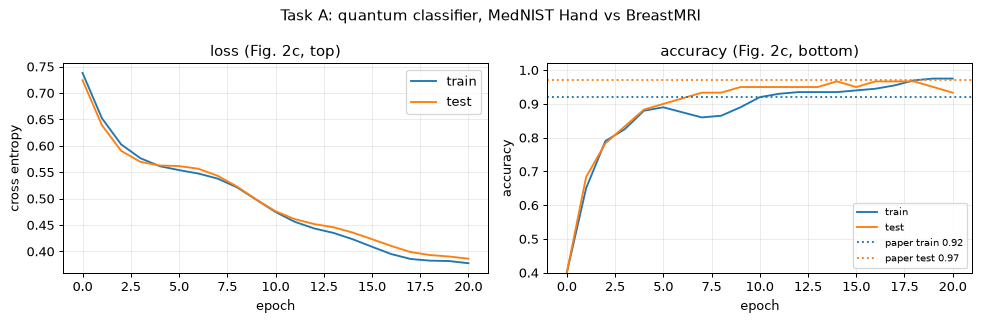

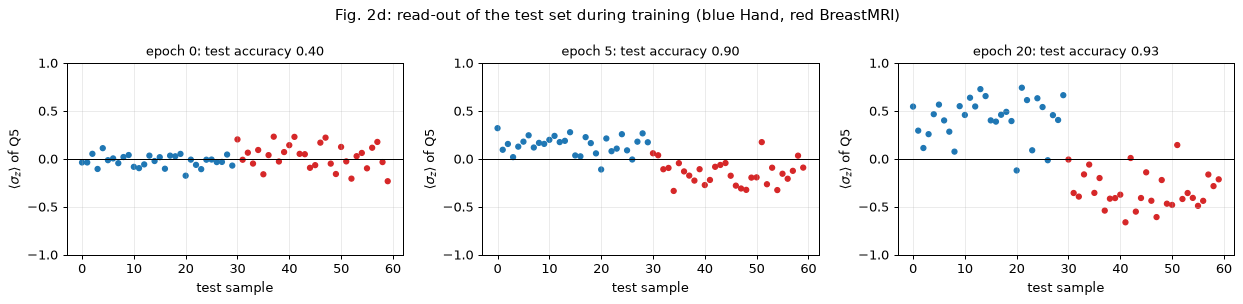

In [24]:
def plot_training(hist, title, paper=None):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    axs[0].plot(hist["epoch"], hist["train_loss"], label="train"); axs[0].plot(hist["epoch"], hist["test_loss"], label="test"); axs[0].set_xlabel("epoch"); axs[0].set_ylabel("cross entropy"); axs[0].legend(); axs[0].set_title("loss (Fig. 2c, top)")
    axs[1].plot(hist["epoch"], hist["train_acc"], label="train"); axs[1].plot(hist["epoch"], hist["test_acc"], label="test")
    if paper: axs[1].axhline(paper[0], c="tab:blue", ls=":", label=f"paper train {paper[0]}"); axs[1].axhline(paper[1], c="tab:orange", ls=":", label=f"paper test {paper[1]}")
    axs[1].set_ylim(0.4, 1.02); axs[1].set_xlabel("epoch"); axs[1].set_ylabel("accuracy"); axs[1].legend(fontsize=8); axs[1].set_title("accuracy (Fig. 2c, bottom)")
    fig.suptitle(title); plt.tight_layout(); plt.show()


plot_training(A0["hist"], "Task A: quantum classifier, MedNIST Hand vs BreastMRI", paper=(0.92, 0.97))
eps_show = [0, min(5, EPOCHS_MED), EPOCHS_MED]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, e in zip(axs, eps_show):
    sigma_z_plot(ax, A0["snaps"][e], DA["yte"].numpy(), f"epoch {e}: test accuracy {A0['hist']['test_acc'][A0['hist']['epoch'].index(e)]:.2f}")
fig.suptitle("Fig. 2d: read-out of the test set during training (blue Hand, red BreastMRI)"); plt.tight_layout(); plt.show()

### A.5 Adversarial examples for the quantum classifier (Fig. 2e, 2f)

Three test images (two correctly classified Hand and Breast images and one more) with their type-1 and type-2 adversarial versions and the circuit's read-out before and after. The perturbation panel is amplified so that it is visible.
Fig. 2f of the paper: $\langle\sigma_z\rangle$ for all adversarial test images (the paper's quantum classifier "misclassifies all of them"). The budget is `EPS_MAIN` per pixel on the 0-1 grey scale.

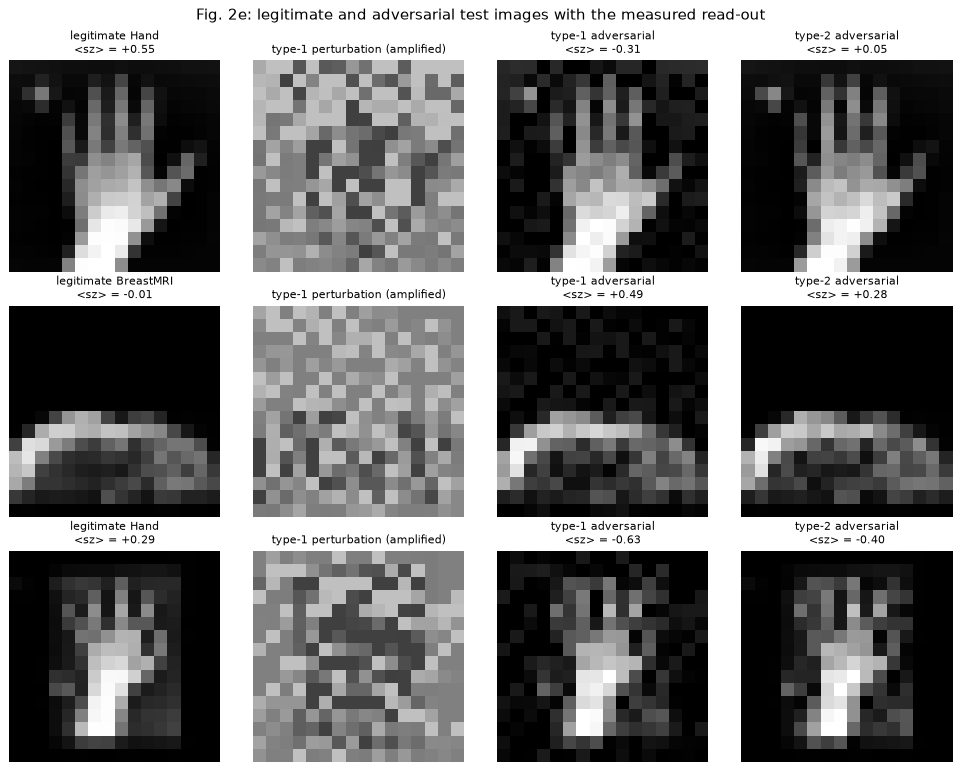

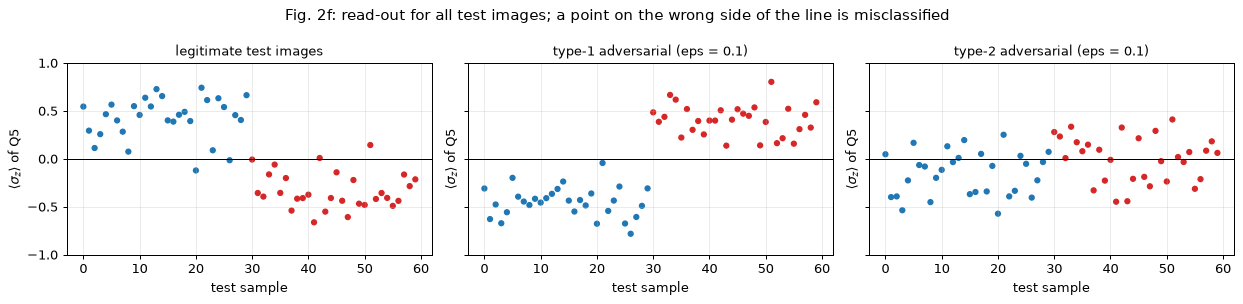

accuracy: legitimate 0.93 | type-1 adversarial 0.00 | type-2 adversarial 0.37   (paper: all type-1 adversarial test images misclassified, i.e. accuracy 0)
size of the type-1 perturbation: max |delta| = 0.100 per pixel, mean L2 norm 1.06 against mean image norm 4.87 (22%)


In [25]:
def show_adversarial_examples(A, D, names, n_show=3):
    qm = A["model"]; yte = D["yte"]
    with torch.no_grad():
        z0, z1, z2 = qm.z(D["Xte"]).numpy(), qm.z(A["adv_te1"]).numpy(), qm.z(A["adv_te2"]).numpy()
    pick = [int(np.where(yte.numpy() == 0)[0][0]), int(np.where(yte.numpy() == 1)[0][0]), int(np.where(yte.numpy() == 0)[0][1])][:n_show]
    fig, axs = plt.subplots(n_show, 4, figsize=(11, 2.9 * n_show))
    for r, i in enumerate(pick):
        x = D["Xte"][i, :256].reshape(16, 16).numpy(); a1 = A["adv_te1"][i, :256].reshape(16, 16).numpy(); a2 = A["adv_te2"][i, :256].reshape(16, 16).numpy()
        for c, (img, ttl) in enumerate(((x, f"legitimate {names[int(yte[i])]}\n<sz> = {z0[i]:+.2f}"), (np.clip(0.5 + (a1 - x) / (2 * EPS_MAIN) * 0.5, 0, 1), "type-1 perturbation (amplified)"),
                                         (a1, f"type-1 adversarial\n<sz> = {z1[i]:+.2f}"), (a2, f"type-2 adversarial\n<sz> = {z2[i]:+.2f}"))):
            axs[r, c].imshow(img, cmap="gray", vmin=0, vmax=1); axs[r, c].axis("off"); axs[r, c].set_title(ttl, fontsize=9)
    fig.suptitle("Fig. 2e: legitimate and adversarial test images with the measured read-out"); plt.tight_layout(); plt.show()
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
    sigma_z_plot(axs[0], z0, yte.numpy(), "legitimate test images"); sigma_z_plot(axs[1], z1, yte.numpy(), f"type-1 adversarial (eps = {EPS_MAIN})"); sigma_z_plot(axs[2], z2, yte.numpy(), f"type-2 adversarial (eps = {EPS_MAIN})")
    fig.suptitle("Fig. 2f: read-out for all test images; a point on the wrong side of the line is misclassified"); plt.tight_layout(); plt.show()


show_adversarial_examples(A0, DA, ["Hand", "BreastMRI"])
print(f"accuracy: legitimate {A0['test_acc']:.2f} | type-1 adversarial {A0['adv1_test_acc']:.2f} | type-2 adversarial {A0['adv2_test_acc']:.2f}   (paper: all type-1 adversarial test images misclassified, i.e. accuracy 0)")
print(f"size of the type-1 perturbation: max |delta| = {A0['linf1']:.3f} per pixel, mean L2 norm {A0['l2_1']:.2f} against mean image norm {A0['l2_clean']:.2f} ({A0['l2_1']/A0['l2_clean']:.0%})")

### A.6 The same attack on classical models, the attack ladder and the budget sweep

All models see the same 256 pixels and are attacked by the same procedure with the same $\varepsilon$ (`EPS_MAIN`). If the quantum circuit is much easier to fool than a classical model on identical inputs, that is a property of this circuit and this input encoding; it is not a statement about quantum models in general.
The attack ladder is the gradient-masking check (see the tools section): the numbers for a model must not *improve* as the attack changes from a gradient method to a gradient-free one.

mean over 2 seed(s); attack: l_inf budget 0.1, 12 Adam ascent steps


,model,train acc,test acc,acc under type-1,acc under type-2
0,quantum circuit (10 qubits),0.97 +- 0.00,0.94 +- 0.01,0.00 +- 0.00,0.43 +- 0.07
1,logistic regression,1.00 +- 0.00,1.00 +- 0.00,1.00 +- 0.00,1.00 +- 0.00
2,RBF SVM,1.00 +- 0.00,1.00 +- 0.00,1.00 +- 0.00,1.00 +- 0.00
3,MLP 256-32-1,1.00 +- 0.00,0.99 +- 0.01,0.44 +- 0.01,0.96 +- 0.01



Attack ladder (accuracy on a balanced test subset of 24 images, budget 0.10; seed 0). Lower = stronger attack:


,clean,FGSM (1 step),PGD,"PGD, 2 restarts",SPSA (no gradients)
quantum circuit,1.00,0.83,0.00,0.00,0.67
"quantum, adversarially trained",0.96,0.83,0.00,0.00,0.67
logistic regression,1.00,1.00,1.00,1.00,1.00
RBF SVM,1.00,1.00,1.00,1.00,1.00
MLP 256-32-1,1.00,1.00,0.50,0.50,1.00
MLP adversarially trained,1.00,1.00,0.33,0.33,1.00


gradient masking suspected (SPSA more than 0.05 below the best gradient attack): {'quantum circuit': np.False_, 'quantum, adversarially trained': np.False_, 'logistic regression': np.False_, 'RBF SVM': np.False_, 'MLP 256-32-1': np.False_, 'MLP adversarially trained': np.False_}


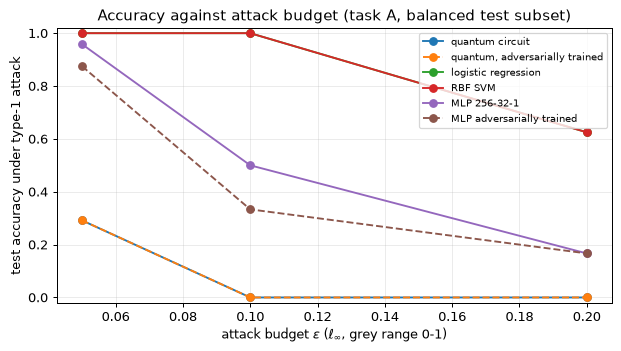

In [26]:
rows = []
for nm, key in (("quantum circuit (10 qubits)", None), ("logistic regression", "logistic regression"), ("RBF SVM", "RBF SVM"), ("MLP 256-32-1", "MLP 256-32-1")):
    vals = []
    for A in RES_A:
        if key is None: vals.append([A["train_acc"], A["test_acc"], A["adv1_test_acc"], A["adv2_test_acc"]])
        else: c = A["classical"][key]; vals.append([c["clean_train"], c["clean"], c["adv1"], c["adv2"]])
    v = np.array(vals); rows.append(dict(model=nm, **{k: f"{v[:, j].mean():.2f}" + (f" +- {v[:, j].std():.2f}" if len(v) > 1 else "") for j, k in enumerate(["train acc", "test acc", "acc under type-1", "acc under type-2"])}))
print(f"mean over {len(RES_A)} seed(s); attack: l_inf budget {EPS_MAIN}, {ATTACK_STEPS} Adam ascent steps")
display(pd.DataFrame(rows))
print("\nAttack ladder (accuracy on a balanced test subset of %d images, budget %.2f; seed 0). Lower = stronger attack:" % (DIAG_N, EPS_MAIN))
display(A0["ladder"].round(2))
lad = A0["ladder"]; flags = []
for nm in lad.index:
    gradient_best = lad.loc[nm, ["PGD", f"PGD, {N_RESTARTS} restarts"]].min(); flags.append(lad.loc[nm, "SPSA (no gradients)"] < gradient_best - 0.05)
print("gradient masking suspected (SPSA more than 0.05 below the best gradient attack):", dict(zip(lad.index, flags)))
fig, ax = plt.subplots(figsize=(7, 4))
for nm, row in A0["sweep"].iterrows(): ax.plot(row.index, row.values, marker="o", label=nm, ls="--" if "trained" in nm else "-")
ax.set_xlabel(r"attack budget $\varepsilon$ ($\ell_\infty$, grey range 0-1)"); ax.set_ylabel("test accuracy under type-1 attack"); ax.set_ylim(-0.02, 1.02); ax.legend(fontsize=8)
ax.set_title("Accuracy against attack budget (task A, balanced test subset)"); plt.tight_layout(); plt.show()

### A.7 Adversarial training (Fig. 4)

Following Algorithms 5 and 6: one type-1 adversarial image is made for every training image against the trained model, the 260 parameters are re-initialised, and the circuit is trained again on batches of 10 legitimate plus 10 adversarial images.
Fig. 4a plots the accuracy on the legitimate and on the adversarial test images per epoch. **Important detail:** the paper's adversarial test images were generated against the *original* classifier and stay fixed ("static"); this is the curve of Fig. 4a.
A defence must also survive an attacker who targets the *retrained* classifier ("fresh" attack), which the paper does not test. Both are reported.

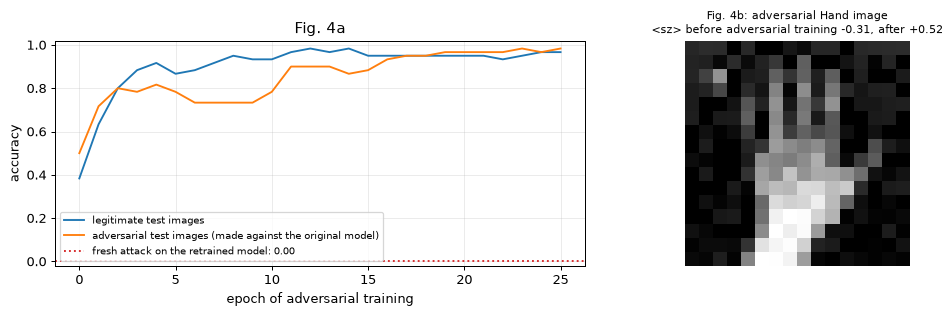

,evaluation of the adversarially trained circuit,accuracy
0,legitimate test images,0.96 +- 0.01
1,static type-1 (made against original model),0.96 +- 0.02
2,static type-2 (made against original model),0.94 +- 0.01
3,fresh type-1 attack on the retrained model,0.03 +- 0.03
4,fresh type-2 attack on the retrained model,0.42 +- 0.02
5,"(baseline) adversarially trained MLP, fresh ty...",0.26


Before adversarial training: type-1 adversarial accuracy 0.00 | after (static): 0.96 | after (fresh): 0.03


In [27]:
H = A0["hist_at"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(H["epoch"], H["acc_legit"], label="legitimate test images"); axs[0].plot(H["epoch"], H["acc_adv"], label="adversarial test images (made against the original model)")
axs[0].axhline(A0["at_fresh1"], c="tab:red", ls=":", label=f"fresh attack on the retrained model: {A0['at_fresh1']:.2f}")
axs[0].set_ylim(-0.02, 1.02); axs[0].set_xlabel("epoch of adversarial training"); axs[0].set_ylabel("accuracy"); axs[0].legend(fontsize=8); axs[0].set_title("Fig. 4a")
cand = np.where((A0["model"].predict(DA["Xte"]) == DA["yte"].long()).numpy() & (A0["model"].predict(A0["adv_te1"]) != DA["yte"].long()).numpy())[0]
i = int(cand[0]) if len(cand) else 0
z_before = A0["model"].z(A0["adv_te1"][i:i + 1]).item(); z_after = A0["model_at"].z(A0["adv_te1"][i:i + 1]).item()
axs[1].imshow(A0["adv_te1"][i, :256].reshape(16, 16).numpy(), cmap="gray", vmin=0, vmax=1); axs[1].axis("off")
axs[1].set_title(f"Fig. 4b: adversarial {['Hand','BreastMRI'][int(DA['yte'][i])]} image\n<sz> before adversarial training {z_before:+.2f}, after {z_after:+.2f}", fontsize=9)
plt.tight_layout(); plt.show()
rows = []
for nm, key in (("legitimate test images", "at_legit"), ("static type-1 (made against original model)", "at_static1"), ("static type-2 (made against original model)", "at_static2"),
                ("fresh type-1 attack on the retrained model", "at_fresh1"), ("fresh type-2 attack on the retrained model", "at_fresh2")):
    v = np.array([A[key] for A in RES_A]); rows.append({"evaluation of the adversarially trained circuit": nm, "accuracy": f"{v.mean():.2f}" + (f" +- {v.std():.2f}" if len(v) > 1 else "")})
v = np.array([A["classical"]["MLP adversarially trained"]["fresh_adv1"] for A in RES_A]); rows.append({"evaluation of the adversarially trained circuit": "(baseline) adversarially trained MLP, fresh type-1 attack", "accuracy": f"{v.mean():.2f}"})
display(pd.DataFrame(rows))
print("Before adversarial training: type-1 adversarial accuracy", f"{np.mean([A['adv1_test_acc'] for A in RES_A]):.2f}", "| after (static):", f"{np.mean([A['at_static1'] for A in RES_A]):.2f}", "| after (fresh):", f"{np.mean([A['at_fresh1'] for A in RES_A]):.2f}")

### A.8 A noise proxy for the chip

On the real device the adversarial images are generated on a classical computer and then sent through a *noisy* circuit; the paper stresses that the attack survives the noise. We cannot rerun the chip, but we can simulate the
logical circuit with depolarizing gate errors set to the paper's benchmark values (Table S1): single-qubit Pauli error 0.08 % per $R_x$, 0.03 % per (virtual) $R_z$, and 1.1 % per CNOT (CZ 0.72 % plus two Hadamards of about 0.19 % each).
Qiskit Aer evolves the 10-qubit density matrix exactly. This is a **proxy**: it ignores T1/T2 decoherence, crosstalk, leakage, the shorter compiled circuit and readout correction, so it says nothing about the hardware numbers.

In [28]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error


def paper_noise_model(e1=0.0008, ez=0.0003, e2=0.0072 + 2 * (2 * 0.0008 + 0.0003)):
    """CHOICE: Pauli errors of Table S1 turned into depolarizing channels (lambda = e d^2 / (d^2 - 1))."""
    nm = NoiseModel(basis_gates=["rx", "rz", "cx", "id"])
    lam = lambda e, d: e * d * d / (d * d - 1)
    nm.add_all_qubit_quantum_error(depolarizing_error(lam(e1, 2), 1), ["rx"])
    nm.add_all_qubit_quantum_error(depolarizing_error(lam(ez, 2), 1), ["rz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(lam(e2, 4), 2), ["cx"])
    return nm


qc_noisy = qc_med.copy(); qc_noisy.save_density_matrix([OBS_Q], label="rho")
sim_noisy = AerSimulator(method="density_matrix", noise_model=paper_noise_model(), max_parallel_threads=1)
t0 = time.time(); qc_noisy_t = transpile(qc_noisy, sim_noisy, optimization_level=0); print(f"transpiled once in {time.time()-t0:.0f} s")


def noisy_z(X, theta, x_scale):
    out = []
    for x in X:
        bound = qc_noisy_t.assign_parameters(dict(zip(par_med, rotation_angles(SPEC_MED, x.numpy(), theta, x_scale))))
        rho = np.asarray(sim_noisy.run(bound).result().data(0)["rho"]); out.append((rho[0, 0] - rho[1, 1]).real)
    return np.array(out)


sub = torch.cat([torch.where(DA["yte"] == c)[0][:N_NOISE // 2] for c in (0, 1)])
t0 = time.time()
zs = {k: (A0["model"].z(X[sub]).detach().numpy(), noisy_z(X[sub], A0["theta"], X_SCALE)) for k, X in (("legitimate", DA["Xte"]), ("type-1 adversarial", A0["adv_te1"]))}
ys = DA["yte"][sub].numpy()
rows = [{"inputs": k, "ideal accuracy": np.mean((ideal < 0) == (ys == 1)), "noisy accuracy": np.mean((noisy < 0) == (ys == 1)), "mean |ideal - noisy| of <sz>": np.abs(ideal - noisy).mean()} for k, (ideal, noisy) in zs.items()]
display(pd.DataFrame(rows).round(3)); print(f"{len(sub)} test images, {time.time()-t0:.0f} s. Paper (hardware): adversarial images made on a classical computer still fool the noisy device.")
NOISE_ROWS = rows

transpiled once in 18 s


,inputs,ideal accuracy,noisy accuracy,mean |ideal - noisy| of <sz>
0,legitimate,1.0,1.0,0.058
1,type-1 adversarial,0.0,0.0,0.121


8 test images, 28 s. Paper (hardware): adversarial images made on a classical computer still fool the noisy device.


## Task B: MNIST digits 0 and 1 (Fig. S13)

Same circuit, same attack, same defence, but only **50 of the 260 parameters are trained** (the rotation layers 3, 6, 11, 17 and 23 of every qubit; the other 210 stay at their random initial value), the learning rate is 0.02, one Adam step per iteration on
10 random training images (5 legitimate + 5 adversarial in adversarial training). The paper reports train / test accuracy 0.98 / 0.99 on the chip after about 200 iterations and an
adversarially retrained classifier that "can defend certain adversarial attacks better".

In [29]:
TRAIN_IDX_MNIST = np.array([L * 10 + q for L in (2, 5, 10, 16, 22) for q in range(10)])       # layers 3, 6, 11, 17, 23 (1-based) of all ten qubits = 50 parameters
rec = max(1, STEPS_MNIST // 20)
RES_B = [run_image_experiment(mnist_split(SEED + s), s, SPEC_MED, X_SCALE, INIT_STD, LR_MNIST, BATCH_MNIST, STEPS_MNIST, STEPS_MNIST, [TRAIN_IDX_MNIST],
                              train_idx=TRAIN_IDX_MNIST, adv_legit=5, adv_adv=5, diagnostics=False, record_every=rec, tag="B")
         for s in range(N_SEEDS)]
B0 = RES_B[0]; DB = mnist_split(SEED)

[B seed 0] train acc 0.84 test acc 0.77 | type-1 adv acc 0.13, type-2 0.52 | adv. trained: legit 0.80, static adv 0.78, fresh adv 0.32 | 387 s


[B seed 1] train acc 0.82 test acc 0.75 | type-1 adv acc 0.33, type-2 0.52 | adv. trained: legit 0.87, static adv 0.88, fresh adv 0.18 | 393 s


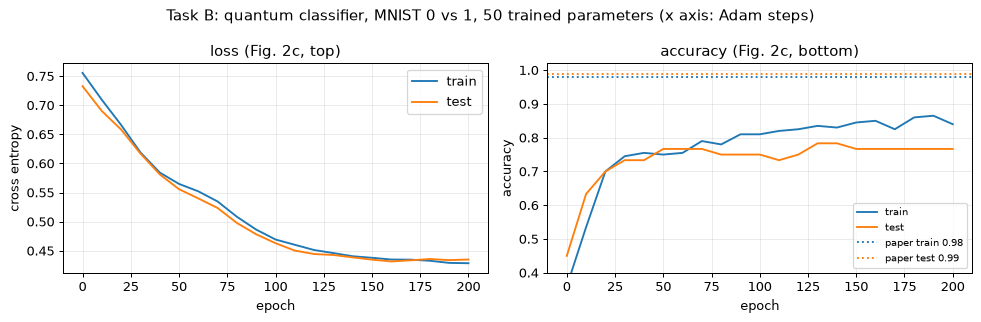

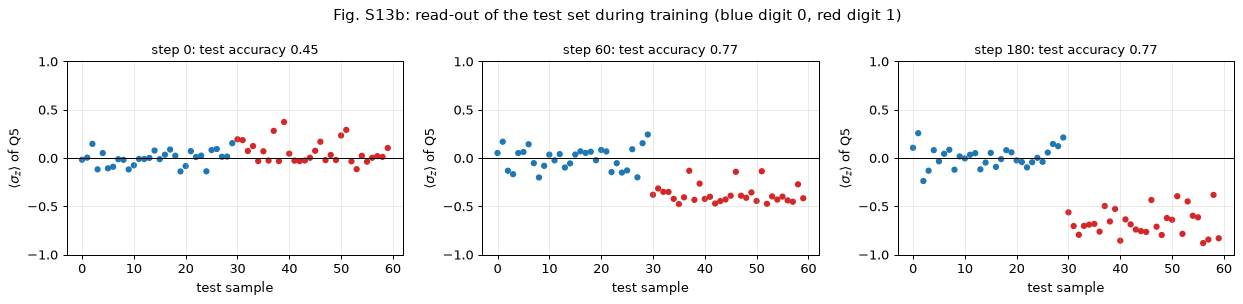

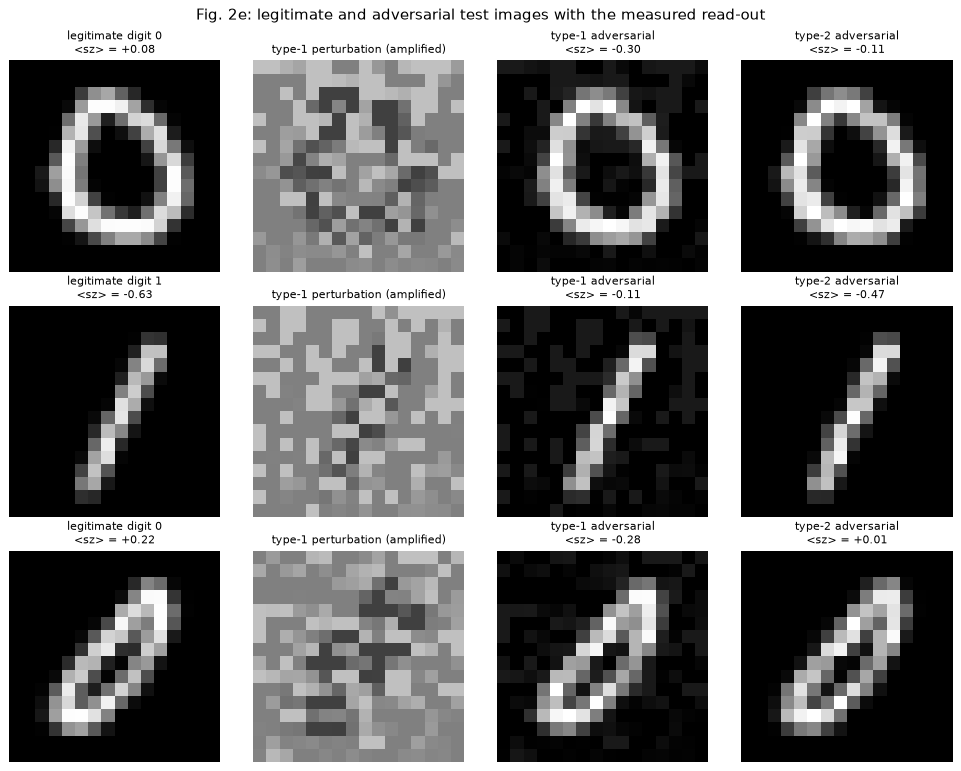

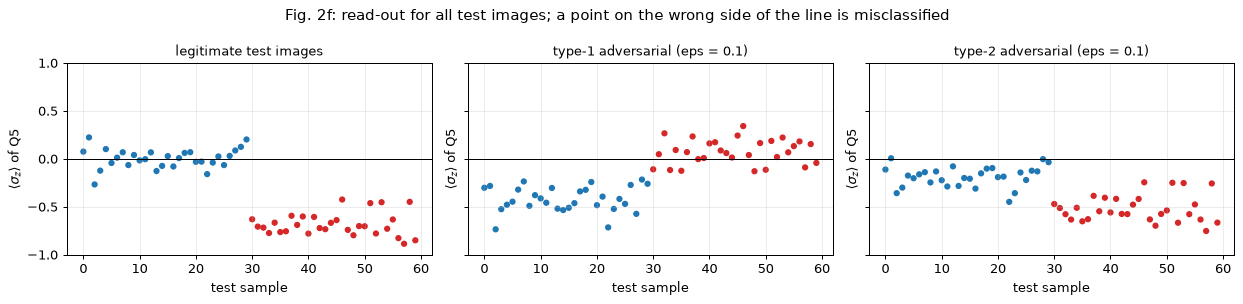

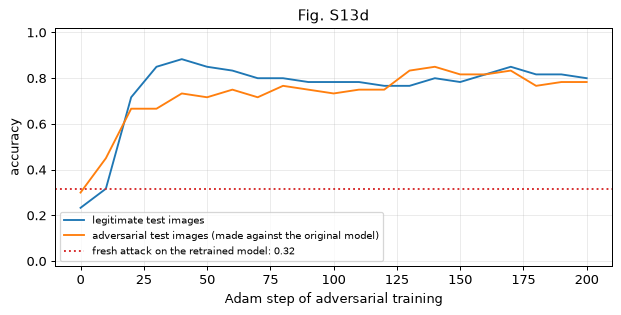

,model,train acc,test acc,acc under type-1,acc under type-2
0,quantum circuit (10 qubits),0.83 +- 0.01,0.76 +- 0.01,0.23 +- 0.10,0.52 +- 0.00
1,logistic regression,1.00 +- 0.00,0.98 +- 0.02,0.97 +- 0.00,0.97 +- 0.00
2,RBF SVM,1.00 +- 0.00,0.99 +- 0.01,0.97 +- 0.00,0.97 +- 0.01
3,MLP 256-32-1,1.00 +- 0.00,0.99 +- 0.01,0.83 +- 0.03,0.98 +- 0.02


,evaluation of the adversarially trained circuit,accuracy
0,legitimate test images,0.83
1,static type-1 (made against original model),0.83
2,static type-2 (made against original model),0.82
3,fresh type-1 attack on the retrained model,0.25
4,fresh type-2 attack on the retrained model,0.56


In [30]:
plot_training(B0["hist"], "Task B: quantum classifier, MNIST 0 vs 1, 50 trained parameters (x axis: Adam steps)", paper=(0.98, 0.99))
ep_show = [min(B0["hist"]["epoch"], key=lambda e: abs(e - f * STEPS_MNIST)) for f in (0, 0.3, 0.9)]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, e in zip(axs, ep_show):
    sigma_z_plot(ax, B0["snaps"][e], DB["yte"].numpy(), f"step {e}: test accuracy {B0['hist']['test_acc'][B0['hist']['epoch'].index(e)]:.2f}")
fig.suptitle("Fig. S13b: read-out of the test set during training (blue digit 0, red digit 1)"); plt.tight_layout(); plt.show()
show_adversarial_examples(B0, DB, ["digit 0", "digit 1"])
H = B0["hist_at"]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(H["epoch"], H["acc_legit"], label="legitimate test images"); ax.plot(H["epoch"], H["acc_adv"], label="adversarial test images (made against the original model)")
ax.axhline(B0["at_fresh1"], c="tab:red", ls=":", label=f"fresh attack on the retrained model: {B0['at_fresh1']:.2f}")
ax.set_ylim(-0.02, 1.02); ax.set_xlabel("Adam step of adversarial training"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); ax.set_title("Fig. S13d"); plt.tight_layout(); plt.show()
rows = []
for nm, key in (("quantum circuit (10 qubits)", None), ("logistic regression", "logistic regression"), ("RBF SVM", "RBF SVM"), ("MLP 256-32-1", "MLP 256-32-1")):
    vals = [[A["train_acc"], A["test_acc"], A["adv1_test_acc"], A["adv2_test_acc"]] if key is None else
            [A["classical"][key]["clean_train"], A["classical"][key]["clean"], A["classical"][key]["adv1"], A["classical"][key]["adv2"]] for A in RES_B]
    v = np.array(vals); rows.append(dict(model=nm, **{k: f"{v[:, j].mean():.2f}" + (f" +- {v[:, j].std():.2f}" if len(v) > 1 else "") for j, k in enumerate(["train acc", "test acc", "acc under type-1", "acc under type-2"])}))
display(pd.DataFrame(rows))
rows = [{"evaluation of the adversarially trained circuit": nm, "accuracy": f"{np.mean([A[key] for A in RES_B]):.2f}"} for nm, key in
        (("legitimate test images", "at_legit"), ("static type-1 (made against original model)", "at_static1"), ("static type-2 (made against original model)", "at_static2"),
         ("fresh type-1 attack on the retrained model", "at_fresh1"), ("fresh type-2 attack on the retrained model", "at_fresh2"))]
display(pd.DataFrame(rows))

## Task C: quantum data, thermal against localized states (Fig. 3)

The classifier receives the *state itself* (no encoding), applies five blocks of $R_x R_z R_x$ rotations and two CNOT layers per block (150 parameters in ten groups of 15), and reads $\langle\sigma_z\rangle$ of Q5.
The attack is Algorithm 8: a layer of three small rotations per qubit is inserted *before* the Hamiltonian evolution, so the adversarial state is again a legitimate-looking output of the Aubry-Andre dynamics. The size of the perturbation is
bounded by the paper ($|\delta_i|\le 0.5$), so there is no free budget to choose here.

### C.1 Training (Fig. 3c)

trained in 117 s | train accuracy 0.91, test accuracy 0.80 after 30 epochs (paper: near perfect after about 30 steps)


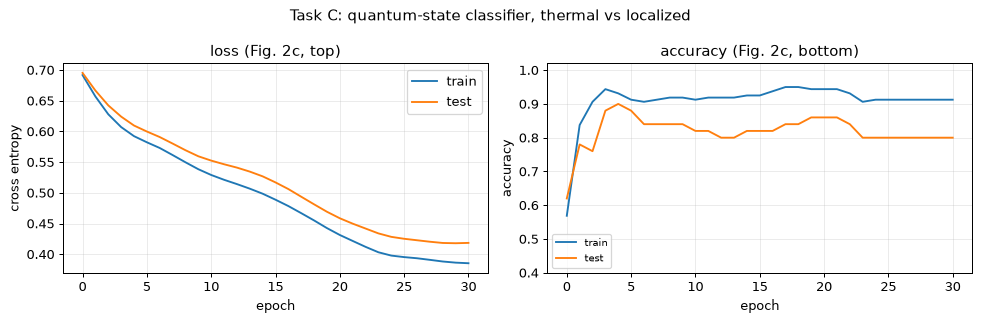

In [31]:
GROUPS_Q = [np.array([i for i in range(150) if i % 10 == q]) for q in range(10)]          # ten groups of 15 parameters, one per qubit (paper)
INIT_Q = None                                       # CHOICE: uniform [0, 2 pi) start (a normal(0, 0.3) start trained worse in development runs)
fwd_q = make_state_forward(SPEC_Q)
t0 = time.time()
theta_q, hist_q, snaps_q = train_group_wise(fwd_q, 150, QTR["psi"], QTR["y"], QTE["psi"], QTE["y"], LR_Q, EPOCHS_Q, GROUPS_Q, BATCH_Q, SEED, theta0=init_theta(SEED + 5, 150, INIT_Q), eval_n=300)
q_train_acc, q_test_acc = acc_of(fwd_q, QTR["psi"], QTR["y"], theta_q), acc_of(fwd_q, QTE["psi"], QTE["y"], theta_q)
print(f"trained in {time.time()-t0:.0f} s | train accuracy {q_train_acc:.2f}, test accuracy {q_test_acc:.2f} after {EPOCHS_Q} epochs (paper: near perfect after about 30 steps)")
plot_training(hist_q, "Task C: quantum-state classifier, thermal vs localized")

### C.2 The attack on quantum states (Algorithm 8) and the same attack on classical models

`quantum_state_attack` maximises the cross entropy over the 30 perturbation angles $\psi$ ($\delta=0.5\sin\psi$, start at $\psi=0$ = identity) by Adam ascent. The exact evolution $U_{AA}$ is applied by sector, so the gradient flows through the physics.
**CHOICE:** the attack returns the *first* iterate on the optimisation path that the model misclassifies (the smallest perturbation found along the way); if no iterate fools the model it returns the iterate of highest loss. The paper only says that
the adversarial states "differ slightly" from the legitimate ones, which a loss-maximising iterate that uses the whole angle range would not do; both variants are compared below.
The evaluation set is (i) the first 10 thermal + 10 localized states of the training set, mirroring Fig. 3d (no filtering by correctness), and (ii) the whole test set.

**Classical baselines on the same objects.** Logistic regression, RBF-SVM and an MLP receive the ten local magnetizations $\langle\sigma_z^k\rangle$ of the state (what the experiment measures in Fig. 3b) and are attacked in exactly the same way:
the attacker can only choose the same 30 angles, and the perturbed state is propagated by the same physics. **Label-preservation check (not in the paper):** an independent physical rule, "the Neel pattern persists",
with the threshold learned on legitimate *training* states, must still assign the true label to the adversarial states; otherwise the attacker has changed the physics and not just fooled the classifier.

In [32]:
def quantum_state_attack(loss_state_fn, pred_fn, Ust, y, steps, lr=0.1, kappa=KAPPA, seed=0, restart=False, spsa=False):
    """Algorithm 8 (spsa=False: Adam ascent on the 30 angles psi) or a gradient-free variant (spsa=True).
    Returns {'first': (states, psi), 'best': (states, psi)}: the first iterate that fools pred_fn (fallback: best-loss iterate) and the best-loss iterate."""
    g = torch.Generator().manual_seed(seed); B = len(y)
    psi = (torch.rand(B, N_Q, 3, generator=g, dtype=torch.float64) * 2 - 1) * 0.5 if restart else torch.zeros(B, N_Q, 3, dtype=torch.float64)
    best_L, best_psi = torch.full((B,), -1e9, dtype=torch.float64), psi.clone()
    first_psi, fooled = psi.clone(), torch.zeros(B, dtype=torch.bool)

    def state_of(p):
        return apply_sector_unitaries(Ust, perturbation_product_state(p, kappa))

    def book(L, st, p):
        nonlocal best_L, best_psi, first_psi, fooled
        with torch.no_grad():
            better = L.detach() > best_L; best_L = torch.where(better, L.detach(), best_L); best_psi[better] = p.detach()[better]
            new = (pred_fn(st.detach()) != y.long()) & ~fooled
            first_psi[new] = p.detach()[new]; fooled = fooled | new

    if not spsa:
        psi.requires_grad_(True); opt = torch.optim.Adam([psi], lr=lr, maximize=True)
        for t in range(steps + 1):
            st = state_of(psi); L = loss_state_fn(st, y); book(L, st, psi)
            if t == steps: break
            opt.zero_grad(); L.sum().backward(); opt.step()
    else:
        with torch.no_grad():
            for t in range(steps):
                s = torch.randint(0, 2, psi.shape, generator=g).double() * 2 - 1; c = 0.2
                Lp, Lm = loss_state_fn(state_of(psi + c * s), y), loss_state_fn(state_of(psi - c * s), y)
                psi = psi + lr * torch.sign(((Lp - Lm) / (2 * c)).view(-1, 1, 1) * s)
                st = state_of(psi); book(loss_state_fn(st, y), st, psi)
    with torch.no_grad():
        first_psi[~fooled] = best_psi[~fooled]
        return {"first": (state_of(first_psi), first_psi), "best": (state_of(best_psi), best_psi), "success": float(fooled.double().mean())}


# ---- attack sets: the first 10 thermal + first 10 localized training states (Fig. 3d uses 20 states from the training set), and the whole test set ----
sel20 = np.concatenate([np.where(QTR["y"].numpy() == c)[0][:10] for c in (0, 1)])
atk_sets = {"train20": (QTR, sel20), "test": (QTE, np.arange(len(QTE["y"])))}
t0 = time.time()
UNIT = {k: stack_unitaries([sector_unitaries(Q["V"][i], Q["phi"][i]) for i in idx]) for k, (Q, idx) in atk_sets.items()}
print(f"exact evolution operators for {sum(len(idx) for _, idx in atk_sets.values())} states built in {time.time()-t0:.0f} s")

q_models = {"quantum circuit": None}
FQ_tr, FQ_te = local_z(QTR["psi"]), local_z(QTE["psi"])                                  # 10 local magnetizations per state
for fit in (fit_logreg, fit_svm_rbf, fit_mlp):
    m = fit(FQ_tr, QTR["y"], N_Q, SEED); q_models[m.name] = m
    print(f"{m.name}: train accuracy {m.acc(FQ_tr, QTR['y']):.2f}, test accuracy {m.acc(FQ_te, QTE['y']):.2f} (features: the ten local magnetizations)")


def loss_of(name):
    if name == "quantum circuit":
        th = torch.tensor(theta_q); return lambda st, y: ce_loss_from_z(fwd_q(st, th), y)
    return lambda st, y: q_models[name].loss_fn()(local_z(st), y)


def pred_of(name):
    if name == "quantum circuit":
        th = torch.tensor(theta_q); return lambda st: predict_class(fwd_q(st, th))
    return lambda st: q_models[name].predict(local_z(st))


def acc_of_model(name, st, y):
    return float((pred_of(name)(st) == y.long()).double().mean())


legit_states = {k: Q["psi"][idx] for k, (Q, idx) in atk_sets.items()}
labels = {k: Q["y"][idx] for k, (Q, idx) in atk_sets.items()}
ADV = {}                                                    # ADV[model][set] = {'first': (states, psi), 'best': (states, psi)}
t0 = time.time()
for name in q_models:
    ADV[name] = {k: quantum_state_attack(loss_of(name), pred_of(name), UNIT[k], labels[k], QATK_STEPS) for k in atk_sets}
    print(f"attack on {name}: {time.time()-t0:.0f} s", flush=True)

exact evolution operators for 70 states built in 46 s
logistic regression: train accuracy 0.99, test accuracy 0.90 (features: the ten local magnetizations)
RBF SVM: train accuracy 0.99, test accuracy 0.96 (features: the ten local magnetizations)


MLP 256-32-1: train accuracy 1.00, test accuracy 0.98 (features: the ten local magnetizations)


attack on quantum circuit: 31 s


attack on logistic regression: 50 s


attack on RBF SVM: 66 s


attack on MLP 256-32-1: 83 s


In [33]:
# ---- results table, per class, with the paper's numbers ----
rows = []
for name in q_models:
    r_ = {"model": name}
    for k, lab in (("train20", "20 train states"), ("test", "test set")):
        y_ = labels[k].numpy().astype(int)
        pl = pred_of(name)(legit_states[k]).numpy(); pa = pred_of(name)(ADV[name][k]["first"][0]).numpy()
        for c, cn in ((0, "thermal"), (1, "localized")):
            r_[f"{lab}: {cn} correct (legit -> adv)"] = f"{(pl[y_ == c] == c).mean():.2f} -> {(pa[y_ == c] == c).mean():.2f}"
    rows.append(r_)
display(pd.DataFrame(rows).set_index("model").T)
print("Paper (Fig. 3d, 20 states from the training set): all legitimate states correct; after the attack ALL localized and HALF of the thermal states are misclassified, i.e. correct -> 1.00 -> 0.00 (localized) and 1.00 -> 0.50 (thermal).")

model,quantum circuit,logistic regression,RBF SVM,MLP 256-32-1
20 train states: thermal correct (legit -> adv),0.90 -> 0.00,1.00 -> 1.00,1.00 -> 1.00,1.00 -> 1.00
20 train states: localized correct (legit -> adv),1.00 -> 0.10,1.00 -> 1.00,1.00 -> 1.00,1.00 -> 1.00
test set: thermal correct (legit -> adv),0.60 -> 0.00,0.84 -> 0.84,0.96 -> 0.96,1.00 -> 1.00
test set: localized correct (legit -> adv),1.00 -> 0.16,0.96 -> 0.96,0.96 -> 0.96,0.96 -> 0.96


Paper (Fig. 3d, 20 states from the training set): all legitimate states correct; after the attack ALL localized and HALF of the thermal states are misclassified, i.e. correct -> 1.00 -> 0.00 (localized) and 1.00 -> 0.50 (thermal).


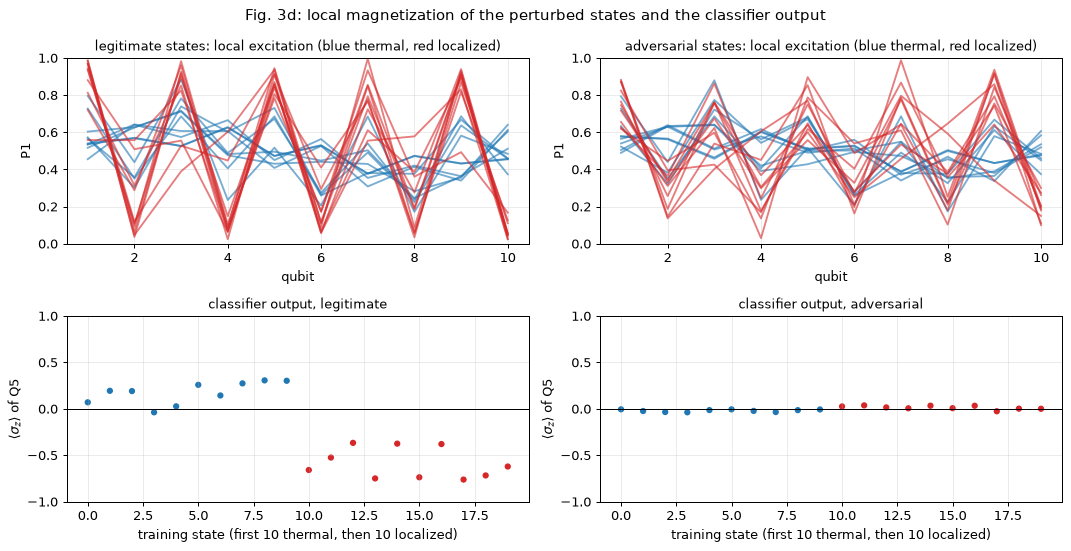

physical rule on legitimate physical rule on adversarial mean fidelity |<legit|adv>|^2 mean |change of P1| per qubit
set             attack variant                                                                                                                                                 
20 train states smallest perturbation that fools the model                        1.00                         0.90                         0.450                         0.075
                highest-loss perturbation                                         1.00                         0.70                         0.174                         0.118
test set        smallest perturbation that fools the model                        0.92                         0.86                         0.509                         0.070
                highest-loss perturbation                                         0.92                         0.64                         0.185                         0.116

(threshold of the physical rule on the staggered magnetization: 0.39, learned on 160 legitimate training states)


In [34]:
# ---- Fig. 3d: local magnetization (P1) of legitimate and adversarial states and the classifier output, 10 thermal + 10 localized training states ----
st_leg, st_adv = legit_states["train20"], ADV["quantum circuit"]["train20"]["first"][0]
y20 = labels["train20"].numpy().astype(int)
P1_leg, P1_adv = (1 - local_z(st_leg)) / 2, (1 - local_z(st_adv)) / 2
with torch.no_grad():
    z_leg, z_adv = eval_z(fwd_q, st_leg, theta_q).numpy(), eval_z(fwd_q, st_adv, theta_q).numpy()
fig, axs = plt.subplots(2, 2, figsize=(12, 6.2))
for ax, P1, ttl in ((axs[0, 0], P1_leg, "legitimate states"), (axs[0, 1], P1_adv, "adversarial states")):
    for i in range(len(y20)): ax.plot(np.arange(1, 11), P1[i].numpy(), c="tab:blue" if y20[i] == 0 else "tab:red", alpha=0.6)
    ax.set_xlabel("qubit"); ax.set_ylabel("P1"); ax.set_ylim(0, 1); ax.set_title(f"{ttl}: local excitation (blue thermal, red localized)", fontsize=10)
for ax, z, ttl in ((axs[1, 0], z_leg, "classifier output, legitimate"), (axs[1, 1], z_adv, "classifier output, adversarial")):
    sigma_z_plot(ax, z, y20, ttl, xlabel="training state (first 10 thermal, then 10 localized)")
fig.suptitle("Fig. 3d: local magnetization of the perturbed states and the classifier output"); plt.tight_layout(); plt.show()

# ---- physical label-preservation check: independent rule on the persistence of the Neel pattern ----
def stagger(st):
    return (local_z(st) * torch.tensor([(-1.0) ** k for k in range(N_Q)])).sum(1).abs() / N_Q


s_tr = stagger(QTR["psi"]).numpy(); ytr_ = QTR["y"].numpy().astype(int)
thr = max(np.sort(s_tr), key=lambda t: np.mean((s_tr > t) == (ytr_ == 1)))                # threshold learned on legitimate TRAINING states
oracle = lambda st: (stagger(st).numpy() > thr).astype(int)
rows = []
for k, lab in (("train20", "20 train states"), ("test", "test set")):
    y_ = labels[k].numpy().astype(int)
    for variant, vname in (("first", "smallest perturbation that fools the model"), ("best", "highest-loss perturbation")):
        st_a = ADV["quantum circuit"][k][variant][0]
        fid = (legit_states[k].conj() * st_a).sum(1).abs() ** 2
        rows.append({"set": lab, "attack variant": vname, "physical rule on legitimate": f"{np.mean(oracle(legit_states[k]) == y_):.2f}", "physical rule on adversarial": f"{np.mean(oracle(st_a) == y_):.2f}",
                     "mean fidelity |<legit|adv>|^2": f"{fid.mean().item():.3f}", "mean |change of P1| per qubit": f"{((local_z(st_a) - local_z(legit_states[k])).abs() / 2).mean().item():.3f}"})
display(pd.DataFrame(rows).set_index(["set", "attack variant"]))
print(f"(threshold of the physical rule on the staggered magnetization: {thr:.2f}, learned on {len(ytr_)} legitimate training states)")

### C.3 Gradient-masking check for the quantum-state attack

Same idea as for the images: the gradient attack of Algorithm 8 against a randomly restarted gradient attack and a gradient-free SPSA attack that uses the same 30 angles and the same bound. All use the test set.
The last column is the lowest accuracy over the three attacks, i.e. the best estimate of a model's real vulnerability. A model whose accuracy under Algorithm 8 is much *higher* than under the restarted or the gradient-free attack
is not robust: the attack that starts at the identity perturbation may simply be stuck close to the identity perturbation.

In [35]:
rows = []
t0 = time.time()
for name in q_models:
    r_ = {"model": name, "clean": acc_of_model(name, legit_states["test"], labels["test"])}
    r_["Algorithm 8 (start at identity)"] = acc_of_model(name, ADV[name]["test"]["first"][0], labels["test"])
    r_["gradient ascent, random restart"] = acc_of_model(name, quantum_state_attack(loss_of(name), pred_of(name), UNIT["test"], labels["test"], QATK_STEPS, restart=True, seed=1)["first"][0], labels["test"])
    r_["SPSA (no gradients)"] = acc_of_model(name, quantum_state_attack(loss_of(name), pred_of(name), UNIT["test"], labels["test"], 2 * QATK_STEPS, lr=0.15, spsa=True, seed=2)["first"][0], labels["test"])
    r_["strongest attack"] = min(r_["Algorithm 8 (start at identity)"], r_["gradient ascent, random restart"], r_["SPSA (no gradients)"])
    rows.append(r_)
ladder_q = pd.DataFrame(rows).set_index("model"); display(ladder_q.round(2))
print(f"({time.time()-t0:.0f} s) masking suspected where SPSA is more than 0.05 below the best gradient attack:",
      {n: bool(ladder_q.loc[n, "SPSA (no gradients)"] < ladder_q.loc[n, ["Algorithm 8 (start at identity)", "gradient ascent, random restart"]].min() - 0.05) for n in ladder_q.index})
weak = [n for n in ladder_q.index if ladder_q.loc[n, "Algorithm 8 (start at identity)"] > ladder_q.loc[n, "strongest attack"] + 0.05]
print("models for which Algorithm 8 started at the identity is NOT the strongest attack (its accuracy overstates their robustness):", weak if weak else "none")

,clean,Algorithm 8 (start at identity),"gradient ascent, random restart",SPSA (no gradients),strongest attack
model,,,,,
quantum circuit,0.80,0.08,0.16,0.26,0.08
logistic regression,0.90,0.90,0.44,0.68,0.44
RBF SVM,0.96,0.96,0.42,0.62,0.42
MLP 256-32-1,0.98,0.98,0.30,0.44,0.30


(242 s) masking suspected where SPSA is more than 0.05 below the best gradient attack: {'quantum circuit': False, 'logistic regression': False, 'RBF SVM': False, 'MLP 256-32-1': False}
models for which Algorithm 8 started at the identity is NOT the strongest attack (its accuracy overstates their robustness): ['logistic regression', 'RBF SVM', 'MLP 256-32-1']


## Task D: "interleaved" against "encoding first" circuits (Fig. S2-S5)

The supplementary information argues for the interleaved block encoding by a simulation: a 540-rotation circuit (270 data angles, 270 trainable parameters) in two layouts, trained on MNIST and Fashion-MNIST (1000 training / 400 test images, Adam, learning rate 0.003, 200 epochs),
with the "encoding first" layout (all data gates first, so the model is a fixed quantum kernel followed by a trainable measurement) clearly worse. The paper gives neither the two classes, nor the batch size, nor the gate order of this benchmark.
`FAST_MODE` uses a few hundred images and a few dozen steps and a larger learning rate (**CHOICE**) because the full budget does not fit on a laptop CPU; the question answered is only the *ordering* of the two layouts.

In [36]:
def pad_to(X, n):
    return torch.cat([X, torch.zeros(len(X), n - X.shape[1], dtype=X.dtype)], 1)


ABL_LR, ABL_BATCH = (0.03 if FAST_MODE else 0.02), 40            # CHOICE: the paper's 0.003 needs about 200 epochs of 1000 images; larger rate for the shorter budget
ABL = {}
t0 = time.time()
for ds_name, Dd in ABL_DATA.items():
    for structure, spec in (("interleaved", SPEC_INT), ("encoding first", SPEC_EF)):
        hs = []
        for s in range(ABL_SEEDS):
            fwd = make_forward(spec, X_SCALE)
            _, h, _ = train_group_wise(fwd, spec.n_param, pad_to(Dd["Xtr"], spec.n_data), Dd["ytr"], pad_to(Dd["Xte"], spec.n_data), Dd["yte"], ABL_LR, ABL_STEPS,
                                       [np.arange(spec.n_param)], ABL_BATCH, 30_000 + s, theta0=init_theta(30_000 + s, spec.n_param, INIT_STD), eval_n=200, record_every=max(1, ABL_STEPS // 15))
            hs.append(h)
        ABL[(ds_name, structure)] = hs
        print(f"{ds_name:32s} {structure:15s} final test accuracy {np.mean([h['test_acc'][-1] for h in hs]):.3f}  ({time.time()-t0:.0f} s)", flush=True)

MNIST 0/1                        interleaved     final test accuracy 0.917  (101 s)


MNIST 0/1                        encoding first  final test accuracy 0.850  (192 s)


Fashion-MNIST T-shirt/trouser    interleaved     final test accuracy 0.967  (316 s)


Fashion-MNIST T-shirt/trouser    encoding first  final test accuracy 0.867  (457 s)


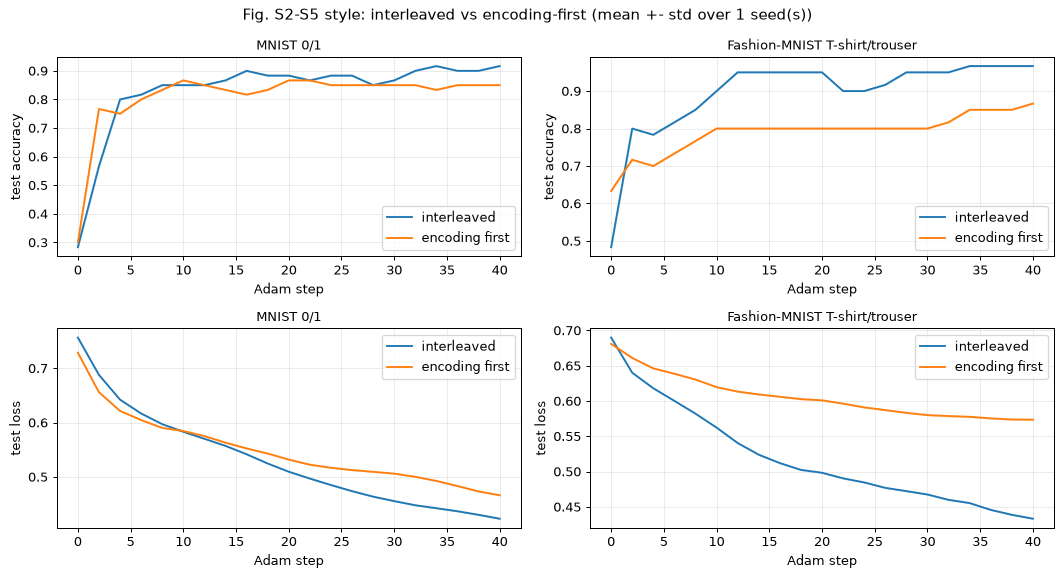

,data,layout,final train accuracy,final test accuracy,final test loss
0,MNIST 0/1,interleaved,0.967,0.917,0.423
1,MNIST 0/1,encoding first,0.850,0.850,0.466
2,Fashion-MNIST T-shirt/trouser,interleaved,0.967,0.967,0.433
3,Fashion-MNIST T-shirt/trouser,encoding first,0.892,0.867,0.574


In [37]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6.5))
for j, ds_name in enumerate(ABL_DATA):
    for structure, col in (("interleaved", "tab:blue"), ("encoding first", "tab:orange")):
        hs = ABL[(ds_name, structure)]; ep = hs[0]["epoch"]
        for r_, key, yl in ((0, "test_acc", "test accuracy"), (1, "test_loss", "test loss")):
            m = np.mean([h[key] for h in hs], 0); sd = np.std([h[key] for h in hs], 0)
            axs[r_, j].plot(ep, m, c=col, label=structure); axs[r_, j].fill_between(ep, m - sd, m + sd, color=col, alpha=0.2)
            axs[r_, j].set_xlabel("Adam step"); axs[r_, j].set_ylabel(yl); axs[r_, j].set_title(ds_name, fontsize=10); axs[r_, j].legend()
fig.suptitle("Fig. S2-S5 style: interleaved vs encoding-first (mean +- std over %d seed(s))" % ABL_SEEDS); plt.tight_layout(); plt.show()
abl_tab = pd.DataFrame([{"data": k[0], "layout": k[1], "final train accuracy": np.mean([h["train_acc"][-1] for h in v]), "final test accuracy": np.mean([h["test_acc"][-1] for h in v]),
                         "final test loss": np.mean([h["test_loss"][-1] for h in v])} for k, v in ABL.items()]).round(3)
display(abl_tab)

## Paper versus this notebook

Every claim of the paper that a simulation can test is computed above and listed here next to the paper's number with a verdict. Rule (as in the other notebooks of this repository): **reproduced** if the notebook is within 2 accuracy points of the paper,
**exceeded** / **not reached** otherwise (the direction says whether the notebook is better or worse *for the claim being made*; for "adversarial accuracy" lower is a stronger attack), **cannot be checked** where the claim is about hardware or about data the paper does not show.
Rows marked *not in paper* are extra checks added here and have no verdict. Paper numbers are hardware experiments (Fig. 2c, 3c, 4a, S13) unless stated; this notebook is an exact noiseless simulation, which is the paper's own upper bound.

In [38]:
def verdict(paper, nb, kind="match", tol=0.02):
    """kind 'match': closeness to the paper's number; 'high': higher is the claim (accuracy); 'low': lower is the claim (accuracy under attack)."""
    if np.isnan(nb): return "cannot be checked"
    if abs(nb - paper) <= tol: return "reproduced"
    if kind == "high": return "exceeded (+%.2f)" % (nb - paper) if nb > paper else "not reached (%.2f)" % (nb - paper)
    if kind == "low": return "exceeded (attack stronger, %.2f)" % (nb - paper) if nb < paper else "not reached (attack weaker, +%.2f)" % (nb - paper)
    return "not reached (%+.2f)" % (nb - paper) if nb < paper else "exceeded (%+.2f)" % (nb - paper)


mean_ = lambda R, k: float(np.mean([r[k] for r in R]))
# physical label-preservation rule on the adversarial test states (task C)
adv_test_states = ADV["quantum circuit"]["test"]["first"][0]
rule_leg = float(np.mean(oracle(legit_states["test"]) == labels["test"].numpy().astype(int))); rule_adv = float(np.mean(oracle(adv_test_states) == labels["test"].numpy().astype(int)))
y20_ = labels["train20"].numpy().astype(int)
with torch.no_grad():
    pl20 = predict_class(eval_z(fwd_q, legit_states["train20"], theta_q)).numpy(); pa20 = predict_class(eval_z(fwd_q, ADV["quantum circuit"]["train20"]["first"][0], theta_q)).numpy()
abl_acc = lambda ds, st: float(np.mean([h["test_acc"][-1] for h in ABL[(ds, st)]]))
inter_better = np.mean([abl_acc(d, "interleaved") - abl_acc(d, "encoding first") for d in ABL_DATA])
noisy_adv = [r for r in NOISE_ROWS if r["inputs"] == "type-1 adversarial"][0]

claims = [
    ("A", "MRI Hand/Breast: train accuracy after 20 epochs", 0.92, mean_(RES_A, "train_acc"), "match"),
    ("A", "MRI Hand/Breast: test accuracy after 20 epochs", 0.97, mean_(RES_A, "test_acc"), "match"),
    ("A", "MRI: test accuracy after 5 epochs", 0.96, mean_(RES_A, "test_acc_ep5"), "match"),
    ("B", "MNIST 0/1: train accuracy", 0.98, mean_(RES_B, "train_acc"), "match"),
    ("B", "MNIST 0/1: test accuracy", 0.99, mean_(RES_B, "test_acc"), "match"),
    ("A", "MRI: accuracy under type-1 attack (paper: all test images misclassified)", 0.0, mean_(RES_A, "adv1_test_acc"), "low"),
    ("B", "MNIST: accuracy under type-1 attack (paper: classifier fails on the examples of Fig. S13c)", 0.0, mean_(RES_B, "adv1_test_acc"), "low"),
    ("C", "Quantum data: train accuracy (near perfect)", 1.0, q_train_acc, "match"),
    ("C", "Quantum data: test accuracy (near perfect)", 1.0, q_test_acc, "match"),
    ("C", "Quantum data: 20 legitimate states from the training set classified correctly", 1.0, float(np.mean(pl20 == y20_)), "match"),
    ("C", "Quantum data: localized states still correct under attack (paper: none)", 0.0, float(np.mean(pa20[y20_ == 1] == 1)), "low"),
    ("C", "Quantum data: thermal states still correct under attack (paper: half)", 0.5, float(np.mean(pa20[y20_ == 0] == 0)), "low"),
    ("C", "Quantum data: perturbed states keep their phase signature (physical rule, test set; legitimate value in brackets)", rule_leg, rule_adv, "match"),
    ("A", "Adversarial training, MRI: accuracy on legitimate test images", 1.0, mean_(RES_A, "at_legit"), "match"),
    ("A", "Adversarial training, MRI: accuracy on the (static) adversarial test images", 1.0, mean_(RES_A, "at_static1"), "match"),
    ("B", "Adversarial training, MNIST: static adversarial accuracy improves over the undefended circuit", mean_(RES_B, "adv1_test_acc") + 0.02, mean_(RES_B, "at_static1"), "high"),
    ("D", "Interleaved layout beats encoding-first layout (test accuracy difference, mean over both datasets)", 0.0, float(inter_better), "high"),
]
rows = [dict(task=t, claim=c, paper=p, notebook=round(n, 3), verdict=verdict(p, n, k)) for t, c, p, n, k in claims]
rows += [
    dict(task="A", claim="(not in paper) MRI: fresh white-box attack on the adversarially trained circuit", paper=np.nan, notebook=round(mean_(RES_A, "at_fresh1"), 3), verdict="no verdict (paper does not test this)"),
    dict(task="B", claim="(not in paper) MNIST: fresh white-box attack on the adversarially trained circuit", paper=np.nan, notebook=round(mean_(RES_B, "at_fresh1"), 3), verdict="no verdict (paper does not test this)"),
    dict(task="A", claim="(proxy) adversarial images stay effective with depolarizing gate noise: accuracy on type-1 images", paper=np.nan, notebook=round(float(noisy_adv["noisy accuracy"]), 3), verdict="cannot be checked (hardware); proxy only"),
    dict(task="hardware", claim="T1 about 150 us; single-/two-qubit gate fidelity above 99.94 % / 99.4 %; dynamical decoupling", paper=np.nan, notebook=np.nan, verdict="cannot be checked"),
    dict(task="hardware", claim="Experimental read-outs of Fig. 2d-f, 3d, 4b, S13b-c for individual samples", paper=np.nan, notebook=np.nan, verdict="cannot be checked (individual hardware samples)"),
]
VERD = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 110)
display(VERD)
cat = VERD["verdict"].map(lambda v: "reproduced" if v.startswith("reproduced") else "exceeded" if v.startswith("exceeded") else "not reached" if v.startswith("not reached") else "cannot be checked" if v.startswith("cannot") else "extra (no verdict)")
print("verdict counts:", dict(cat.value_counts()))
print(f"[task C physical rule on legitimate test states: {rule_leg:.2f}]")

,task,claim,paper,notebook,verdict
0,A,MRI Hand/Breast: train accuracy after 20 epochs,0.920000,0.975,exceeded (+0.05)
1,A,MRI Hand/Breast: test accuracy after 20 epochs,0.970000,0.942,not reached (-0.03)
2,A,MRI: test accuracy after 5 epochs,0.960000,0.883,not reached (-0.08)
3,B,MNIST 0/1: train accuracy,0.980000,0.830,not reached (-0.15)
4,B,MNIST 0/1: test accuracy,0.990000,0.758,not reached (-0.23)
5,A,MRI: accuracy under type-1 attack (paper: all test images misclassified),0.000000,0.000,reproduced
6,B,MNIST: accuracy under type-1 attack (paper: classifier fails on the examples of Fig. S13c),0.000000,0.233,"not reached (attack weaker, +0.23)"
7,C,Quantum data: train accuracy (near perfect),1.000000,0.912,not reached (-0.09)
8,C,Quantum data: test accuracy (near perfect),1.000000,0.800,not reached (-0.20)
9,C,Quantum data: 20 legitimate states from the training set classified correctly,1.000000,0.950,not reached (-0.05)


verdict counts: {'not reached': np.int64(12), 'exceeded': np.int64(4), 'cannot be checked': np.int64(3), 'extra (no verdict)': np.int64(2), 'reproduced': np.int64(1)}
[task C physical rule on legitimate test states: 0.92]


In [39]:
print(f"FAST_MODE = {FAST_MODE} | seeds {N_SEEDS} | task A seed-0 times (s): {', '.join(f'{k} {v:.0f}' for k, v in A0['seconds'].items())} | task B total {B0['seconds']['total']:.0f} s")
print(f"Budgets of this run: images per class (train/test) {N_TR_PC}/{N_TE_PC}, epochs {EPOCHS_MED} (+{EPOCHS_ADV} adversarial), attack steps {ATTACK_STEPS}, quantum states per class {NQ_TR_PC}/{NQ_TE_PC}, ablation steps {ABL_STEPS}.")
print("Budgets of the full run (FAST_MODE = False): 250/50 images per class, 20 + 25 epochs, 20 attack steps, 250/50 quantum states per class, 3 attack restarts, 100 ablation steps (see the configuration cell); about 3 hours on a loaded laptop CPU.")

FAST_MODE = True | seeds 2 | task A seed-0 times (s): train 126, attack 175, total 506 | task B total 387 s
Budgets of this run: images per class (train/test) 100/30, epochs 20 (+25 adversarial), attack steps 12, quantum states per class 80/25, ablation steps 40.
Budgets of the full run (FAST_MODE = False): 250/50 images per class, 20 + 25 epochs, 20 attack steps, 250/50 quantum states per class, 3 attack restarts, 100 ablation steps (see the configuration cell); about 3 hours on a loaded laptop CPU.


## Reading the paper critically

*(Written after the executed run; the numbers are those printed above for this `FAST_MODE = True` run: 100 + 100 training images per class and 30 + 30 test images, 2 seeds, 12 attack steps, quantum data 80 + 80 training states. The run took about 49 minutes on a shared laptop CPU. The paper's sizes and budgets are in the `else` branch of the configuration cell and were not run: they would take about 3 hours.)*

**What the simulation confirms.**
- *The circuit really is fooled.* With a budget of 0.1 on the 0-1 grey scale per pixel, no type-1 test image of the Hand/BreastMRI task is classified correctly (accuracy 0.00 on both seeds), exactly the paper's Fig. 2f. The check for gradient masking finds none: the gradient-free SPSA attack is weaker (accuracy 0.67) than the gradient attack (0.00), restarts change nothing, and accuracy falls monotonically with the budget: 0.29 at 0.05, 0.00 at 0.1 and 0.2 (budget sweep), while logistic regression and the RBF-SVM keep 1.00 up to 0.1 and still have 0.63 at 0.2. The attack is therefore a genuine property of the circuit and not an artefact of a particular optimiser.
- *Type-2 examples* (object area only) are weaker (accuracy 0.43 +- 0.07), consistent with the paper using type-1 examples for the quantitative claims.
- *Interleaved beats encoding first* (Task D): 0.92 against 0.85 on MNIST and 0.97 against 0.87 on Fashion-MNIST, mean difference +0.08. Direction as in Fig. S2-S5, but with one seed, 60 test images and a much shorter budget than the paper's, so it is evidence for the ordering and not for the size of the gap.
- *Noise does not rescue the model* (proxy, 8 images): the adversarial images stay misclassified with depolarizing gate errors at the paper's benchmark values (the read-out moves by only 0.06 to 0.12). This is a proxy for, not a test of, the hardware claim.

**What the simulation does not confirm.**
- *Clean accuracy of MNIST 0/1 (0.83 train, 0.76 test against the paper's 0.98 / 0.99) and of the quantum-data classifier (0.91 / 0.80 against "near perfect").* The MNIST gap is large and not explained by the two seeds (0.77 and 0.75 test accuracy): with 200 training images, 50 trainable parameters out of 260 and 200 Adam steps the circuit is underfitted, and the 210 frozen parameters are random, so the result depends on that random draw. For the quantum data, a separate physical rule that only asks "does the Neel pattern persist?" classifies 0.92 of the test states correctly, so the classes are separable; the classifier of this notebook, which is one rotated $\sigma_z$ read-out with no bias, plateaus near 0.9 on the training states (also with longer training in development runs outside this notebook). Fig. S9, which should fix the quantum-data circuit, is only partly legible, the gate order, the entangling pattern and the Neel state were assumptions, and any of them may explain the gap. This notebook cannot tell which.
- *Adversarial training.* The paper's Fig. 4a is reproduced in its own protocol: after retraining on legitimate plus adversarial images the accuracy on the *fixed* adversarial test images is 0.96 (paper: close to 1) and on legitimate images 0.96. But the paper tests the retrained circuit only on examples that were made against the *original* parameters. An attacker who targets the retrained circuit brings accuracy back to 0.03 (type-1) and 0.42 (type-2), and on MNIST from 0.83 (static) to 0.25 (fresh). An adversarially retrained MLP behaves the same way (0.26 under a fresh attack), and in the budget sweep the adversarially trained circuit has exactly the same accuracy curve as the undefended one. So "immune to adversarial perturbations generated by the same attacking strategy" holds only for a fixed set of examples; it is not robustness. Adversarial training with fixed examples is a data-augmentation step, not a defence against an adaptive attacker.
- *The quantum-state attack is stronger than in the paper:* all thermal states and 90 % of the localized training states are misclassified (paper: half and all). When the attack uses the whole allowed range of angles, the perturbed states are not "slightly different": mean fidelity 0.18 and the physical rule's accuracy on the test states falls from 0.92 to 0.64. Stopping at the first iterate that fools the classifier keeps the fidelity near 0.5 and the physical rule at 0.86. The paper's statement that the perturbation preserves the phase is plausible for the second variant and not for the first; it depends on how far the attack is allowed to run.

**Caveats a reader should keep in mind.**
1. *The attack budget is ours.* The paper never states the size of the perturbation. 0.1 on the grey scale is a 22 % relative L2 change of the 16 x 16 image, visible in the amplified-perturbation panel. "Imperceptible" is therefore not established; the budget sweep shows how the picture changes with epsilon.
2. *Classical models on the same inputs are not vulnerable at this budget* (logistic regression and RBF-SVM keep accuracy 1.00; the MLP drops to 0.44). Hand X-rays and breast MRIs differ so strongly in overall intensity that a linear model is robust, while the circuit, which encodes every pixel as an angle and reads one qubit, is not. The comparison speaks about this circuit and encoding, not about quantum models in general; the paper's argument that vulnerability is generic for high-dimensional data is not tested here.
3. *The quantum-data attack from the identity is a poor attack on classical models:* it leaves them at their clean test accuracy (0.90 to 0.98), but a randomly restarted version of the same attack brings them to 0.30-0.44. Reporting only the paper's procedure would have overstated the robustness of the classical baselines.
4. *Exact simulation, no shot noise, one random draw of data and parameters per seed.* The seeds agree closely on the image tasks but only two were run; the quantum-data and ablation experiments use one. Hardware-only claims (T1, gate fidelities, dynamical decoupling, the individual read-outs of Fig. 2d-f, 3d, 4b, S13b-c) cannot be checked in any notebook.
5. *Data.* The paper's "Hand" and "Breast" images come from Polanco's Medical MNIST; this notebook uses MedNIST, the MONAI release of the same collection (64 x 64), so the pixels are the same kind of data but the exact images drawn may differ.

## Exercises

1. **Budget.** The paper never states how large the perturbation is. Plot test accuracy of the quantum circuit and of the three classical models against $\varepsilon$ (cell A.6) up to $\varepsilon = 0.5$ and find, for each model, the smallest budget that drives accuracy below 10 %. Is the quantum circuit more or less robust than the RBF-SVM on the same pixels?
2. **Encoding scale.** `X_SCALE` was chosen on a validation split. Re-run section A.1 with `X_SCALE = 2 pi` (a pixel difference of 1 becomes a full rotation) and with `X_SCALE = 0.25`. Which one trains, and which one is easier to attack?
3. **Where does the vulnerability sit?** Restrict the type-1 mask to the 64 centre pixels or to the 64 border pixels instead of the object area. Which pixels does the circuit depend on most? Compare with the logistic-regression weights.
4. **A real defence test.** Adversarial training here uses a *fixed* set of adversarial examples. Implement Madry-style training (a fresh attack on the current parameters for every mini-batch) for the circuit and compare its fresh-attack accuracy with the table in A.7.
5. **Quantum data.** Change the perturbation bound `KAPPA` from 0.5 to 0.1 and to 1.0. How does the fraction of thermal and localized states that is misclassified change, and when does the physical rule of C.2 stop agreeing with the true label (the attacker has then changed the physics, not just fooled the classifier)?